## Семинар 5: Диффузионные модели, DDPM

На семинаре разберём прямой и обратный диффузионные процессы и обучим DDPM генерировать изображения.

### План📝:

- Идея диффузионной модели
- Forward Diffusion Process
- Reverse Diffusion Process
- MNIST и архитектура U-Net
- Training and Validation Loop
- Sampling и генерация по условию


In [29]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import clear_output
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")


Device: cuda


### Идея диффузионной модели

Наша цель - научиться генерировать объекты из распределения, похожего на $p_{\text{data}}(\mathbf{x})$.

В диффузионной модели мы строим два процесса:

- **Прямой процесс** $q(\mathbf{x}_t\mid\mathbf{x}_{t-1})$ постепенно разрушает структуру данных, добавляя гауссовский шум.
- **Обратный процесс** $p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1}\mid\mathbf{x}_t)$ превращает шум в данные. 

- При подходящем расписании $\mathbf{x}_T$ становится близким к стандартному нормальному распределению.
- Поэтому генерацию можно начать с $\mathbf{x}_T\sim\mathcal N(\mathbf{0},\mathbf I)$.


Обратный процесс использует **одну сеть с общими весами для всех времён**. Номер шага $t$ передаём ей как дополнительный вход.

<div style="width: 600px; max-width: 100%;">

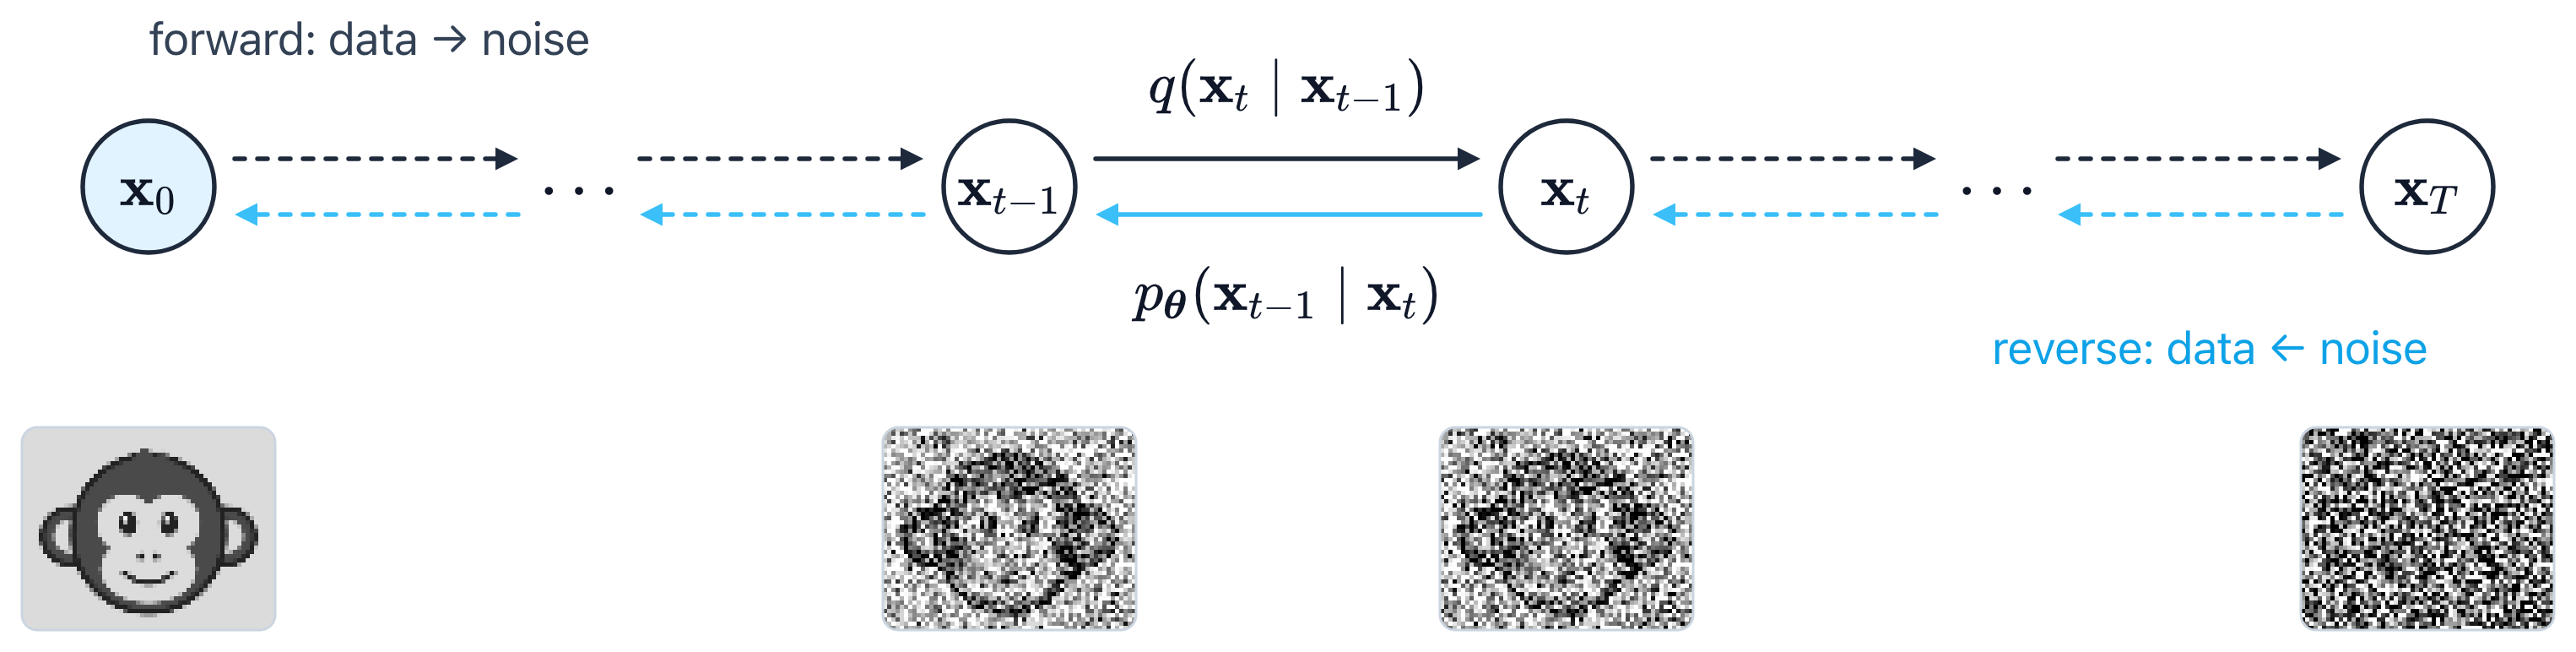

</div>


<div style="background-color:#fff8e1; border-left:4px solid #f5a623; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Вопрос для размышления:** если мы сами задали прямой процесс, почему нельзя просто выполнить его шаги в обратном порядке?
</div>


### Forward Diffusion Process

Прямой процесс задаётся марковской цепью:

$$q(\mathbf{x}_{1:T}\mid\mathbf{x}_0)=\prod_{t=1}^{T}q(\mathbf{x}_t\mid\mathbf{x}_{t-1}).$$

Один переход имеет вид:

<div style="background-color:#f5f7fa; border:1px solid #d0d7de; border-radius:6px; padding:15px; margin:10px 0; text-align:center;">

$$q(\mathbf{x}_t\mid\mathbf{x}_{t-1})=\mathcal N\left(\sqrt{1-\beta_t}\,\mathbf{x}_{t-1},\,\beta_t\mathbf I\right),$$

$$\mathbf{x}_t=\sqrt{1-\beta_t}\,\mathbf{x}_{t-1}+\sqrt{\beta_t}\,\boldsymbol{\epsilon}_t,\qquad \boldsymbol{\epsilon}_t\sim\mathcal N(\mathbf 0,\mathbf I).$$

</div>

$\beta_t$ задаёт **дисперсию** добавляемого шума.

<div style="width: 600px; max-width: 100%;">

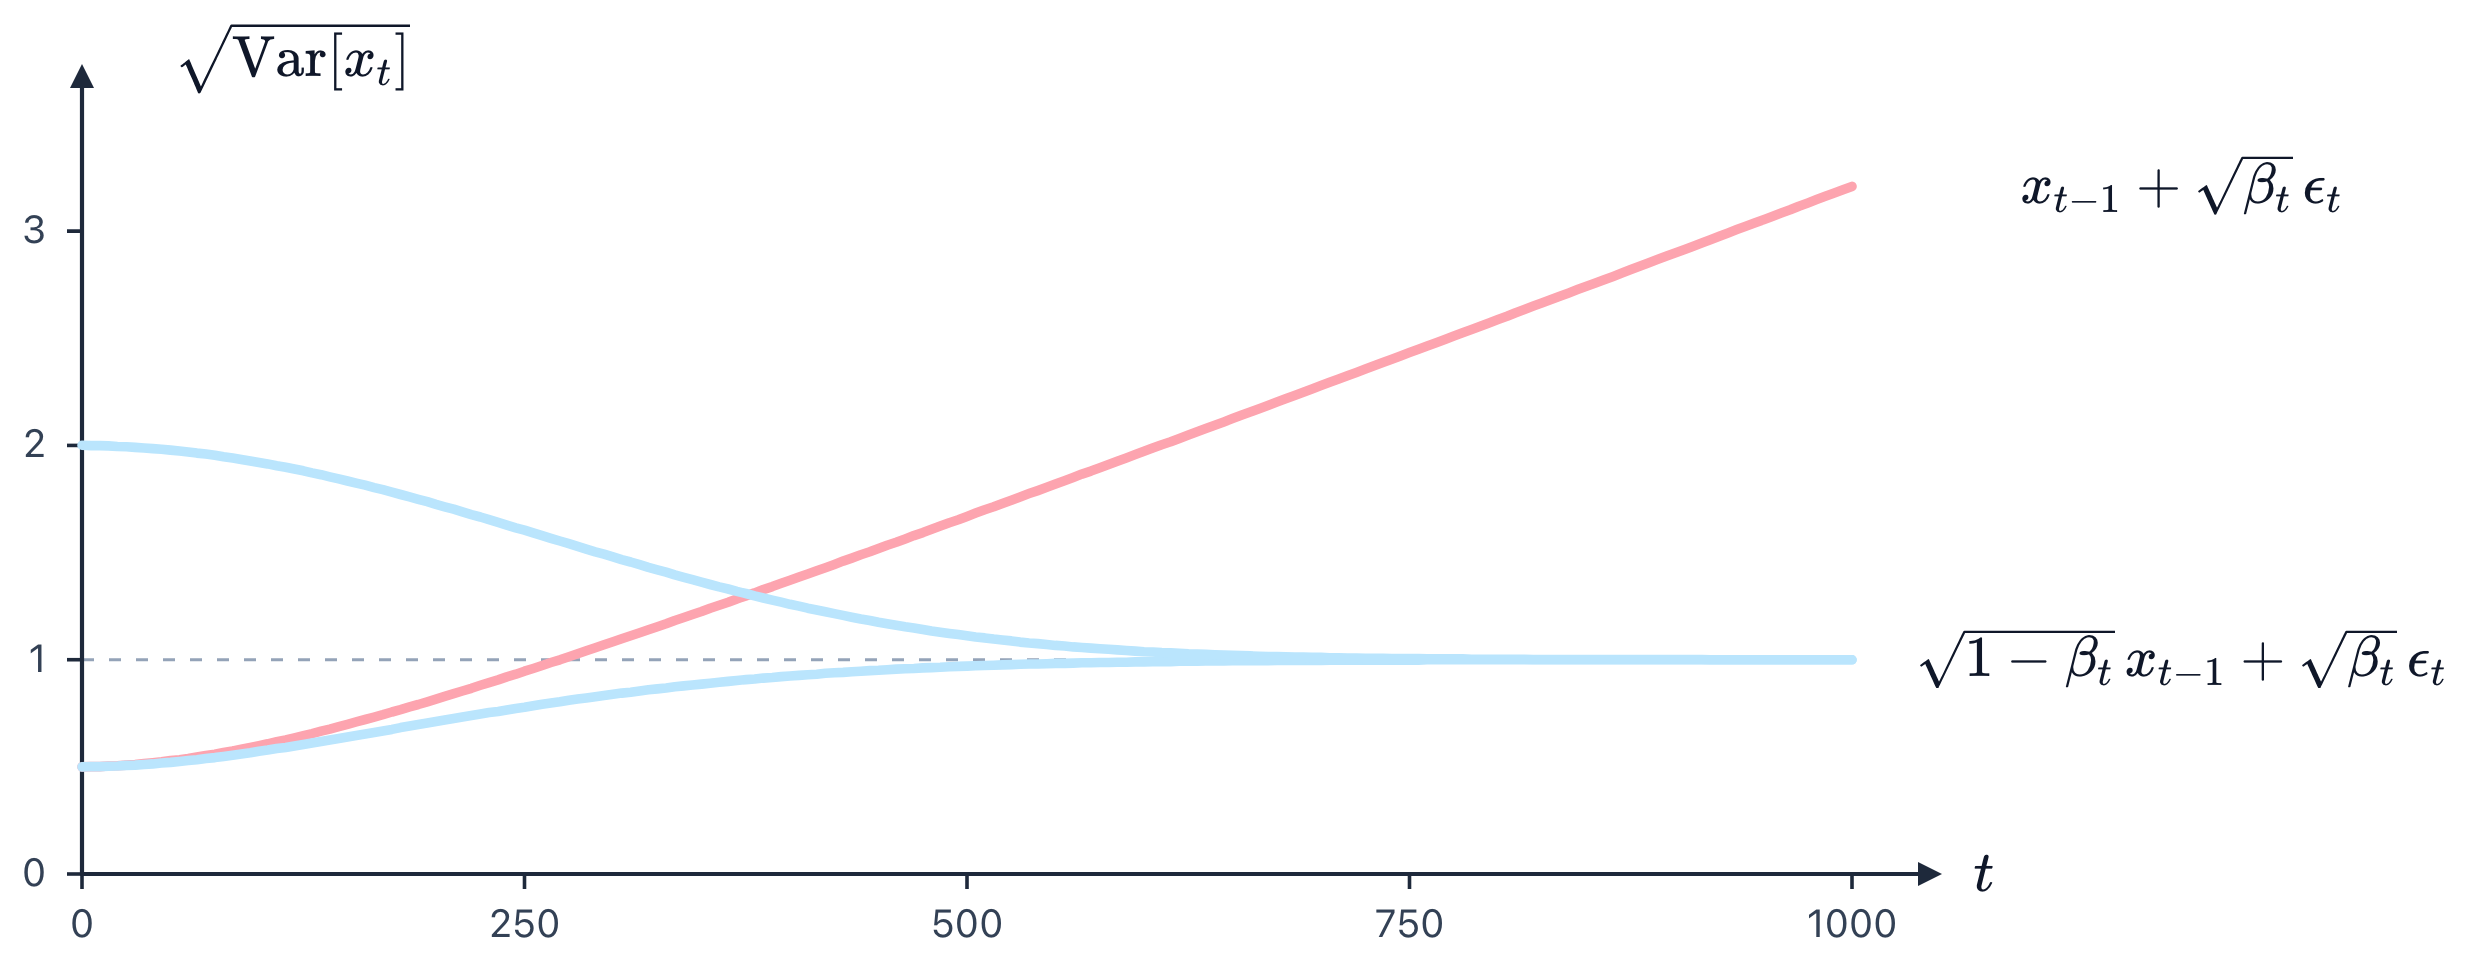

</div>

**Сохранение масштаба:**

- Голубые кривые показывают приближение стандартного отклонения к единице при разных начальных дисперсиях. 
- Множитель $\sqrt{1-\beta_t}$ компенсирует накопление шума.


#### Noise Schedule

Введём обозначения:

$$\alpha_t=1-\beta_t,\qquad \bar\alpha_t=\prod_{s=1}^{t}\alpha_s.$$

- $\alpha_t$ относится к **одному переходу**.
- $\bar\alpha_t$ учитывает **все переходы с 1 по $t$**.

Обычно берут линейное расписание: $T=1000$, $\beta_1=10^{-4}$, $\beta_T=0.02$.

<div style="width: 600px; max-width: 100%;">

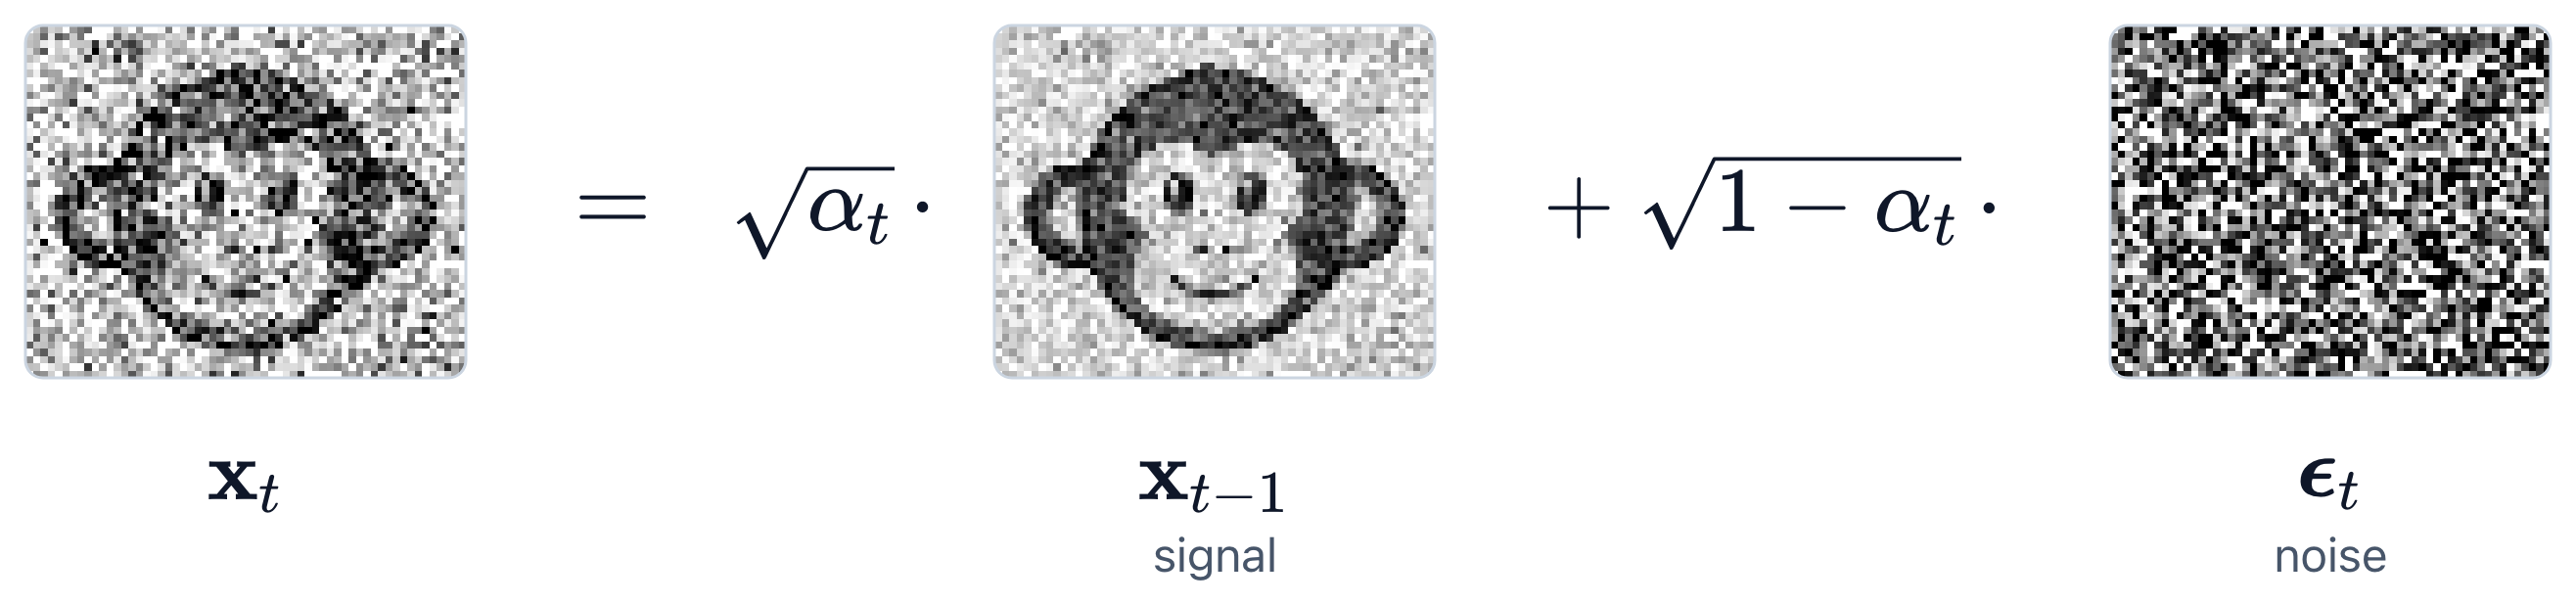

</div>

Новое состояние складывается из ослабленного сигнала и гауссовского шума.

Shape: (1001,)
alpha_bar[0] = 1.000000
alpha_bar[T] = 0.000040


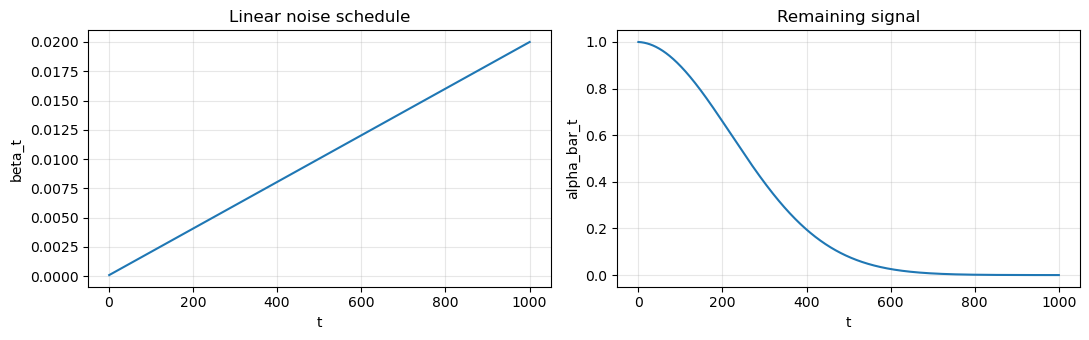

In [30]:
def linear_beta_schedule(T, beta_start=1e-4, beta_end=0.02):
    """Create linear beta_1...beta_T, with beta_0 = 0 for clean data."""
    return torch.cat([torch.zeros(1), torch.linspace(beta_start, beta_end, T)])  # Reserve index 0 for clean data.

def make_schedule(T, beta_start=1e-4, beta_end=0.02):
    """Compute beta, alpha, and cumulative alpha_bar for steps 0...T."""
    betas = linear_beta_schedule(T, beta_start, beta_end)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)  # Track the remaining signal at each step.
    return betas, alphas, alpha_bars

T_REFERENCE = 1000
betas, alphas, alpha_bars = make_schedule(T_REFERENCE)

print(f"Shape: {tuple(betas.shape)}")
print(f"alpha_bar[0] = {alpha_bars[0].item():.6f}")
print(f"alpha_bar[T] = {alpha_bars[-1].item():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(range(1, T_REFERENCE + 1), betas[1:].numpy())
axes[0].set(title="Linear noise schedule", xlabel="t", ylabel="beta_t")
axes[1].plot(alpha_bars.numpy())
axes[1].set(title="Remaining signal", xlabel="t", ylabel="alpha_bar_t")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<div style="background-color:#fff8e1; border-left:4px solid #f5a623; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Вопрос для размышления:** что произойдёт, если уменьшить $T$ до 100, оставив те же начальное и конечное значения $\beta_t$?

</div>


T= 100: alpha_bar[T]=0.363563
T= 400: alpha_bar[T]=0.017473
T=1000: alpha_bar[T]=0.000040


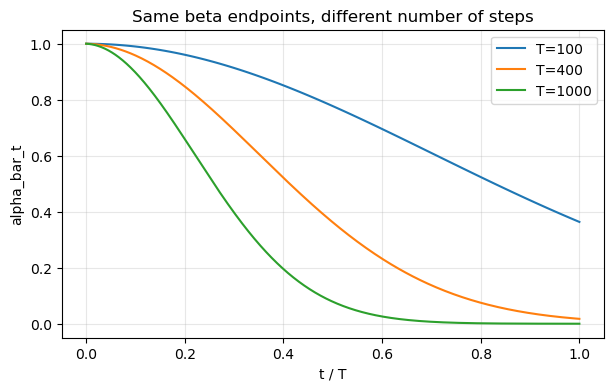

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
for T_example in [100, 400, 1000]:
    _, _, bars = make_schedule(T_example)
    print(f"T={T_example:4d}: alpha_bar[T]={bars[-1].item():.6f}")
    ax.plot(np.linspace(0, 1, T_example + 1), bars.numpy(), label=f"T={T_example}")
ax.set(xlabel="t / T", ylabel="alpha_bar_t", title="Same beta endpoints, different number of steps")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


#### Получение $\mathbf{x}_t$ сразу из $\mathbf{x}_0$

После нескольких переходов мы получаем линейную комбинацию $\mathbf{x}_0$ и независимых гауссовских шумов. Их сумма снова гауссовская. Отсюда:

<div style="background-color:#f5f7fa; border:1px solid #d0d7de; border-radius:6px; padding:15px; margin:10px 0; text-align:center;">

$$q(\mathbf{x}_t\mid\mathbf{x}_0)=\mathcal N\left(\sqrt{\bar\alpha_t}\,\mathbf{x}_0,\,(1-\bar\alpha_t)\mathbf I\right),$$

$$\mathbf{x}_t=\sqrt{\bar\alpha_t}\,\mathbf{x}_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon,\qquad\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,\mathbf I).$$

</div>

Нам не нужно делать $t$ шагов, чтобы получить обучающий пример. Достаточно одного шума и двух коэффициентов. Здесь $\boldsymbol\epsilon$ - **суммарный шум** до шага $t$.


In [32]:
def extract(values, t, x):
    """Select a coefficient per timestep and reshape it for image broadcasting."""
    return values[t].reshape(t.shape[0], *([1] * (x.ndim - 1)))

def q_sample(x_0, t, alpha_bars, noise=None):
    """Sample x_t from clean x_0, timestep t, and Gaussian noise."""
    if noise is None:
        noise = torch.randn_like(x_0)
    bar = extract(alpha_bars, t, x_0)
    return bar.sqrt() * x_0 + (1.0 - bar).sqrt() * noise

alpha_bars = alpha_bars.to(device)
dummy_images = torch.zeros(8, 1, 28, 28, device=device)
t = torch.randint(1, T_REFERENCE + 1, (len(dummy_images),), device=device)
noise = torch.randn_like(dummy_images)
x_t = q_sample(dummy_images, t, alpha_bars, noise)
print(f"Images: {tuple(dummy_images.shape)}, t: {tuple(t.shape)}")
print(f"Extracted coefficients: {tuple(extract(alpha_bars, t, dummy_images).shape)}")
print(f"Noise: {tuple(noise.shape)}, x_t: {tuple(x_t.shape)}")
assert torch.equal(q_sample(dummy_images, torch.zeros_like(t), alpha_bars, noise), dummy_images)


Images: (8, 1, 28, 28), t: (8,)
Extracted coefficients: (8, 1, 1, 1)
Noise: (8, 1, 28, 28), x_t: (8, 1, 28, 28)


<div style="background-color:#eefbf0; border-left:4px solid #22a55e; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Что важно запомнить про прямой процесс:**


- Прямой процесс фиксирован и не содержит обучаемых параметров.
- $\beta_t$ задаёт дисперсию шума одного перехода, $\bar\alpha_t$ описывает сохранение сигнала после всех переходов.
- Получить $x_t$ из $x_0$ можно сразу, без прохода по всей цепочке.
- Для старта генерации из стандартного нормального шума нужно, чтобы $\bar\alpha_T$ было достаточно близко к нулю.


</div>


### Reverse Diffusion Process

При генерации нам доступно только $\mathbf{x}_t$. Поэтому требуется обратный переход $q(\mathbf{x}_{t-1}\mid\mathbf{x}_t)$. Он зависит от неизвестного распределения данных.

Но **во время обучения** мы знаем исходный объект $\mathbf{x}_0$. Условное распределение $q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0)$ вычисляется аналитически:

$$q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0)=\mathcal N(\tilde{\boldsymbol\mu}_t,\tilde\beta_t\mathbf I),$$

$$\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t},$$

$$\tilde{\boldsymbol\mu}_t=
\frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\mathbf{x}_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\mathbf{x}_t.$$

При $t=1$ и известном $\mathbf{x}_0$ дисперсия равна нулю: этот условный переход вырожден. Формулы KL между невырожденными гауссианами далее применяем при $t\ge2$.

- Переход $q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0)$ гауссовский точно.
- Переход без условия на $\mathbf{x}_0$ в общем случае не обязан быть гауссовским.
- При малых шагах диффузии гауссовская модель обратного перехода становится подходящим приближением.

<div style="width: 600px; max-width: 100%;">

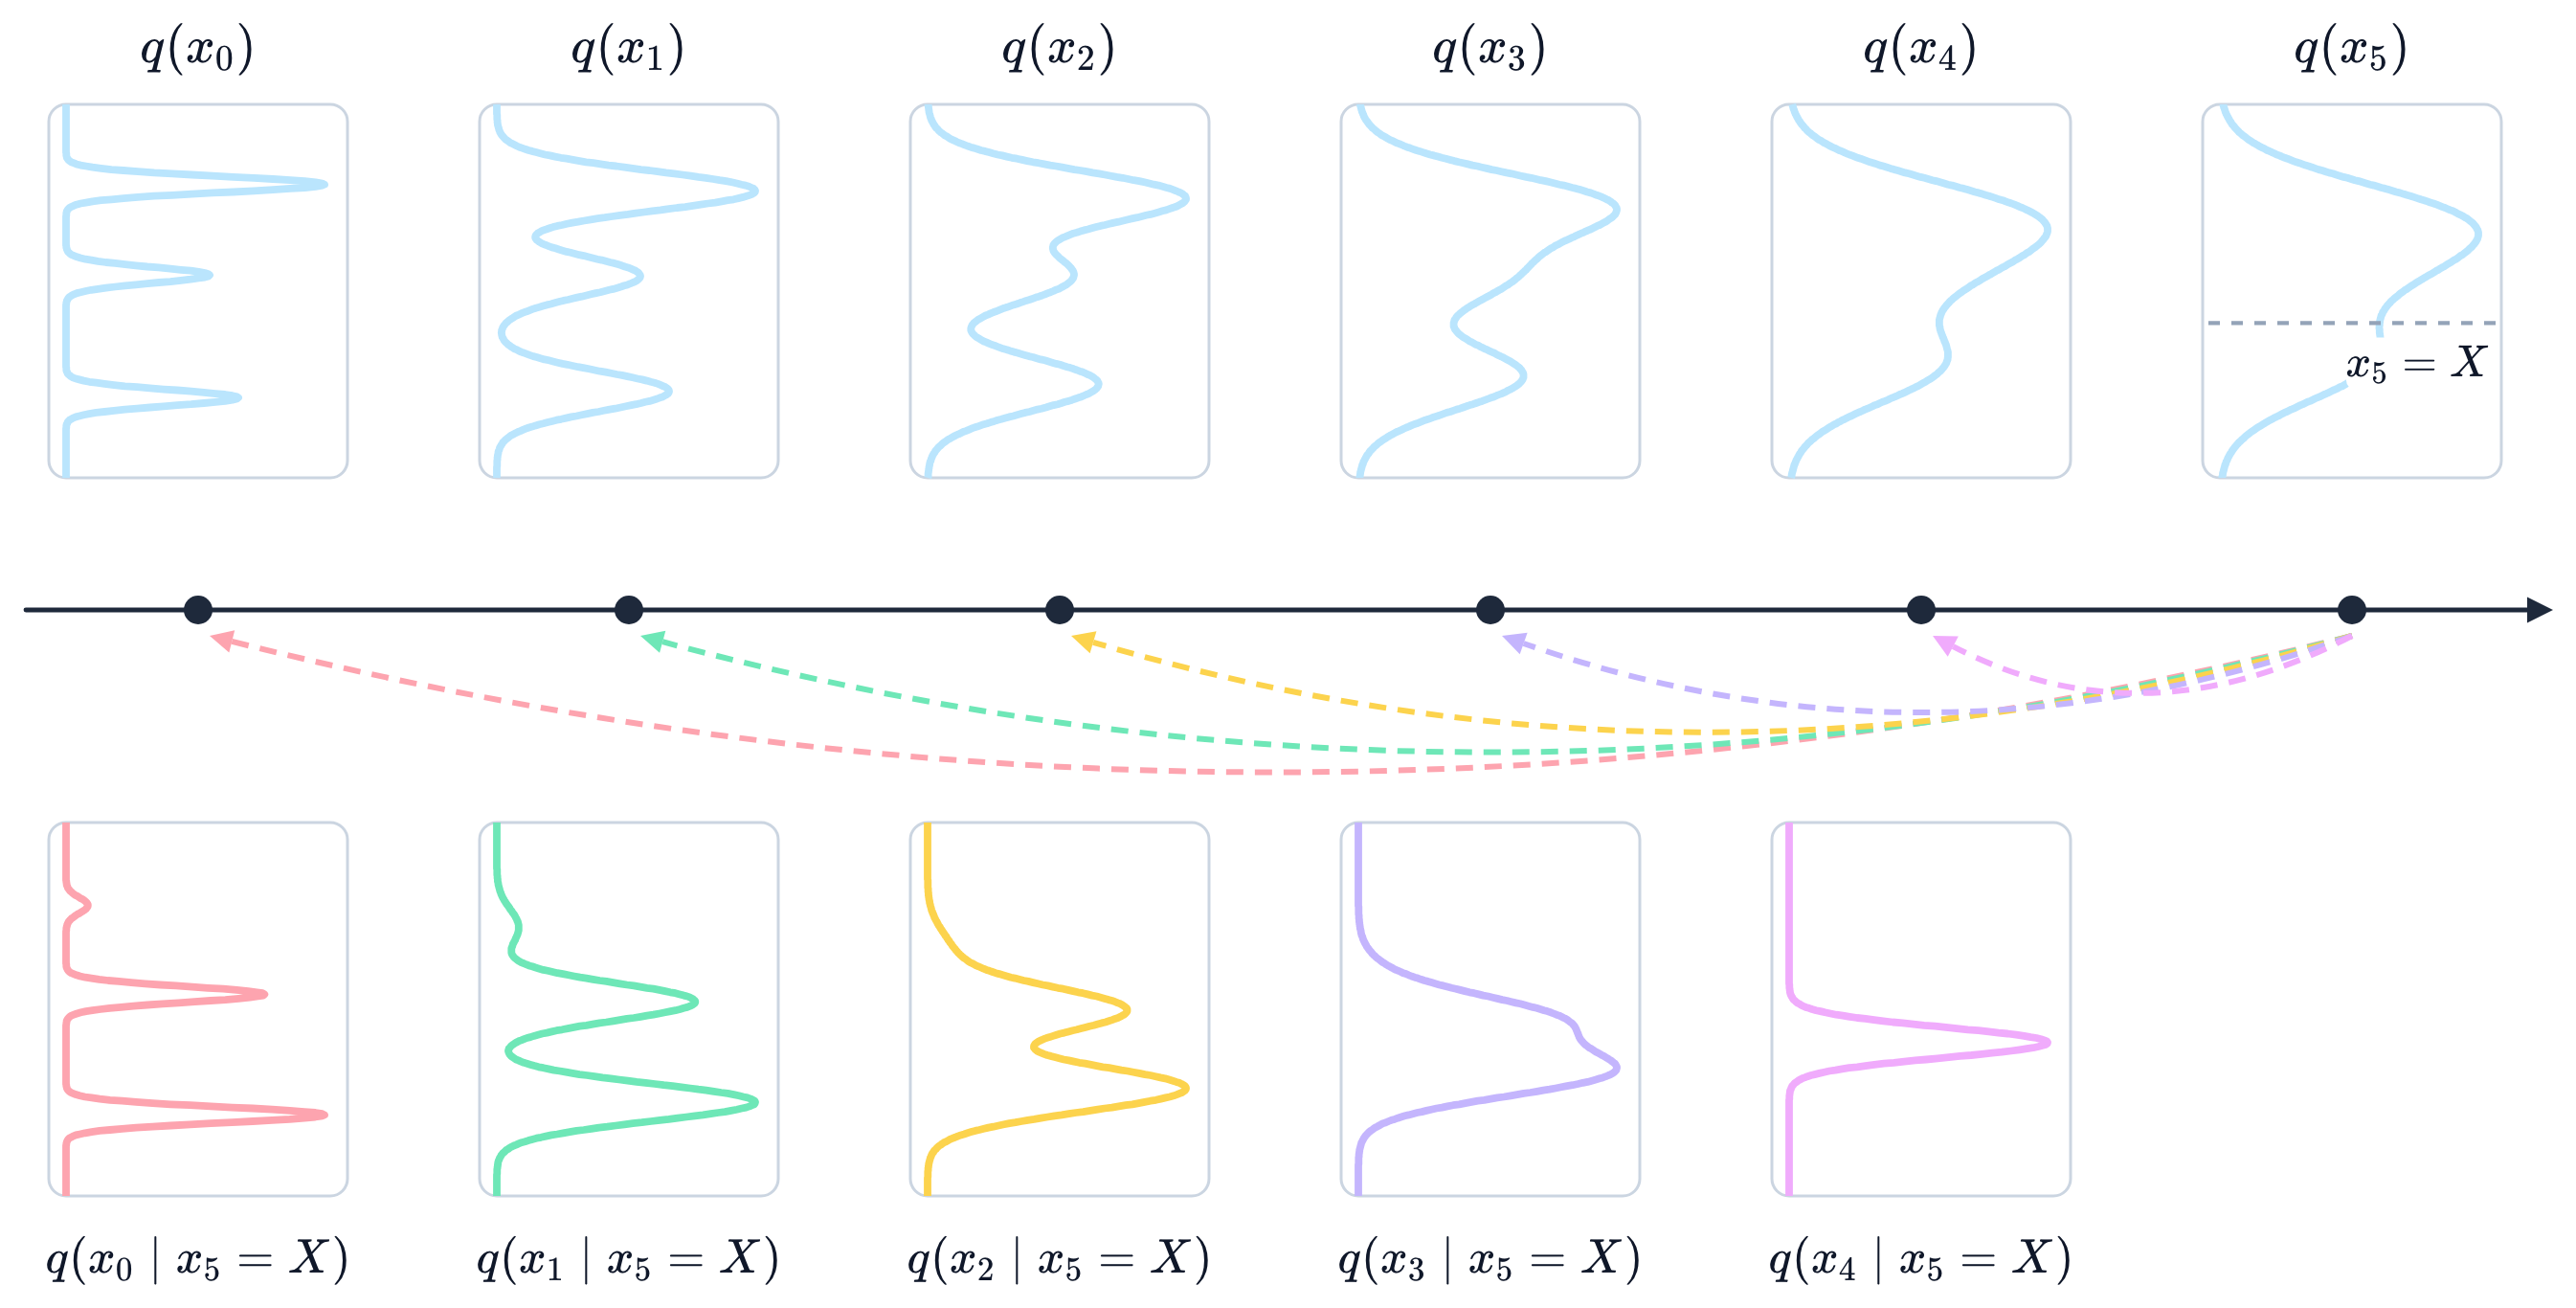

</div>

**Малые обратные переходы:**

- На рисунке справа зафиксировано $x_5=X$. 
- Ближайший обратный переход к $x_4$ можно приближать гауссианой. 
- Условные распределения для более далёких состояний могут быть многомодальными. 

#### Связь с ELBO

Как обсуждалось в лекции, диффузию можно представить как модель со скрытыми переменными $\mathbf{x}_{1:T}$. 

<div style="width: 600px; max-width: 100%;">

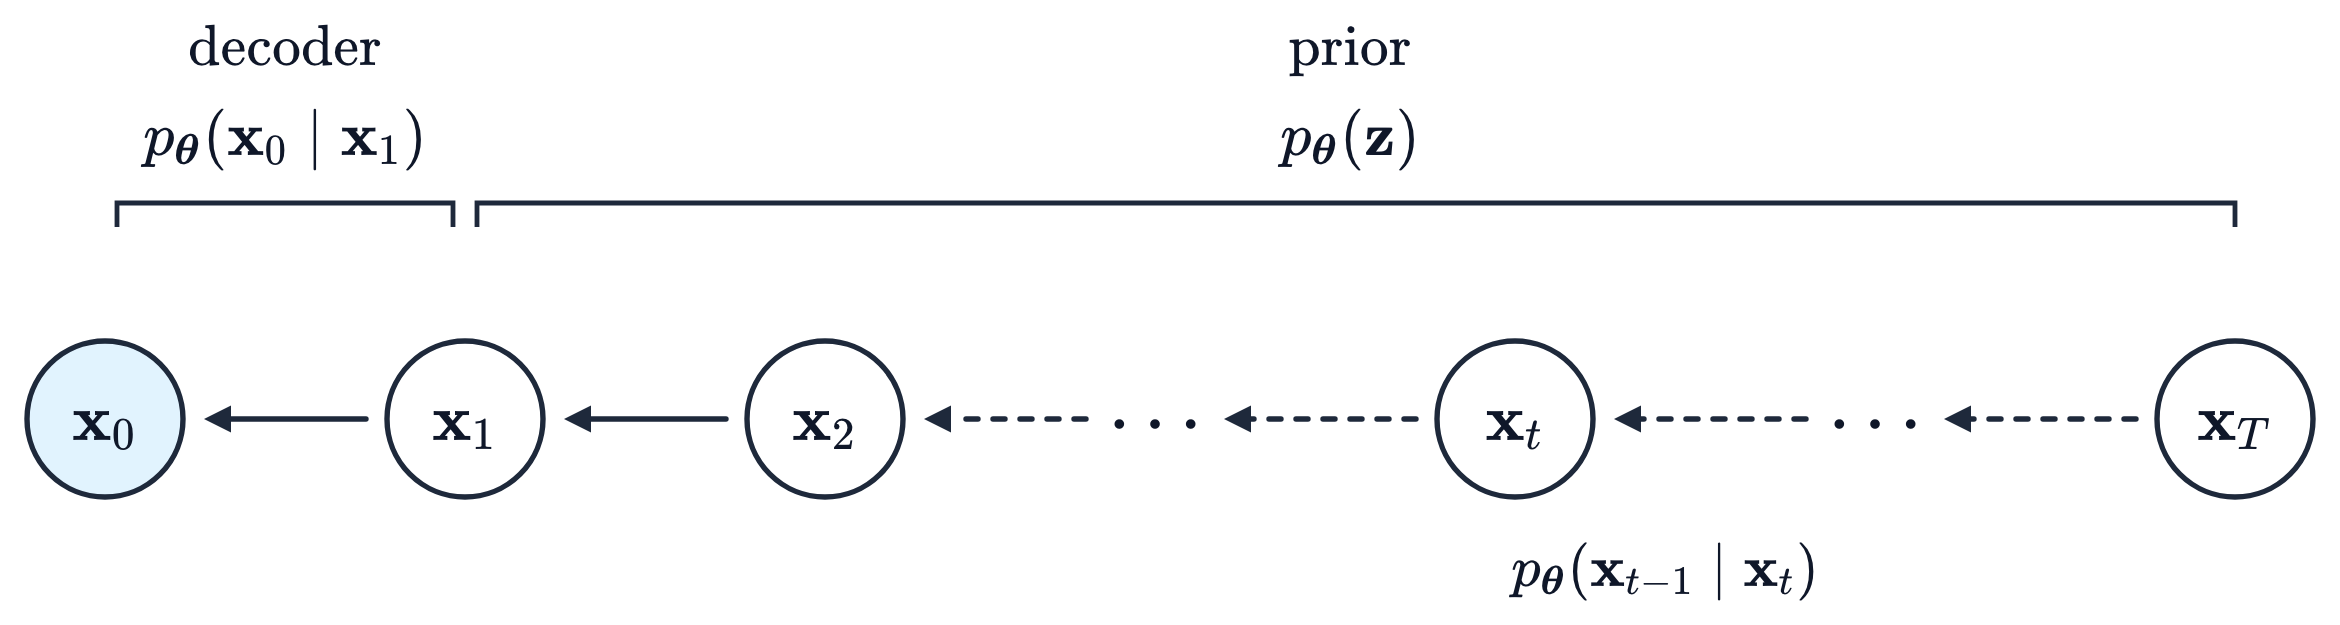

</div>

**Диффузия как модель со скрытыми переменными:**

- Скрытые переменные $\mathbf z$ включают всю цепочку $\mathbf{x}_{1:T}$. 
- Последнему шагу соответствует декодер $p_{\boldsymbol\theta}(\mathbf{x}_0\mid\mathbf{x}_1)$ 
- Остальная обратная цепь вместе с $p(\mathbf{x}_T)$ задаёт prior для $\mathbf z$.

Вариационная нижняя граница раскладывается на:

$$\mathcal L_{\mathrm{VLB}}=
\underbrace{\mathbb E_q\log p_{\boldsymbol\theta}(\mathbf{x}_0\mid\mathbf{x}_1)}_{\text{восстановление}}
-\underbrace{D_{\mathrm{KL}}(q(\mathbf{x}_T\mid\mathbf{x}_0)\Vert p(\mathbf{x}_T))}_{\text{соответствие prior}}
-\underbrace{\sum_{t=2}^{T}\mathbb E_q D_{\mathrm{KL}}(q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0)\Vert p_{\boldsymbol\theta}(\mathbf{x}_{t-1}\mid\mathbf{x}_t))}_{\text{обучение обратных переходов}}.$$

<div style="width: 600px; max-width: 100%;">

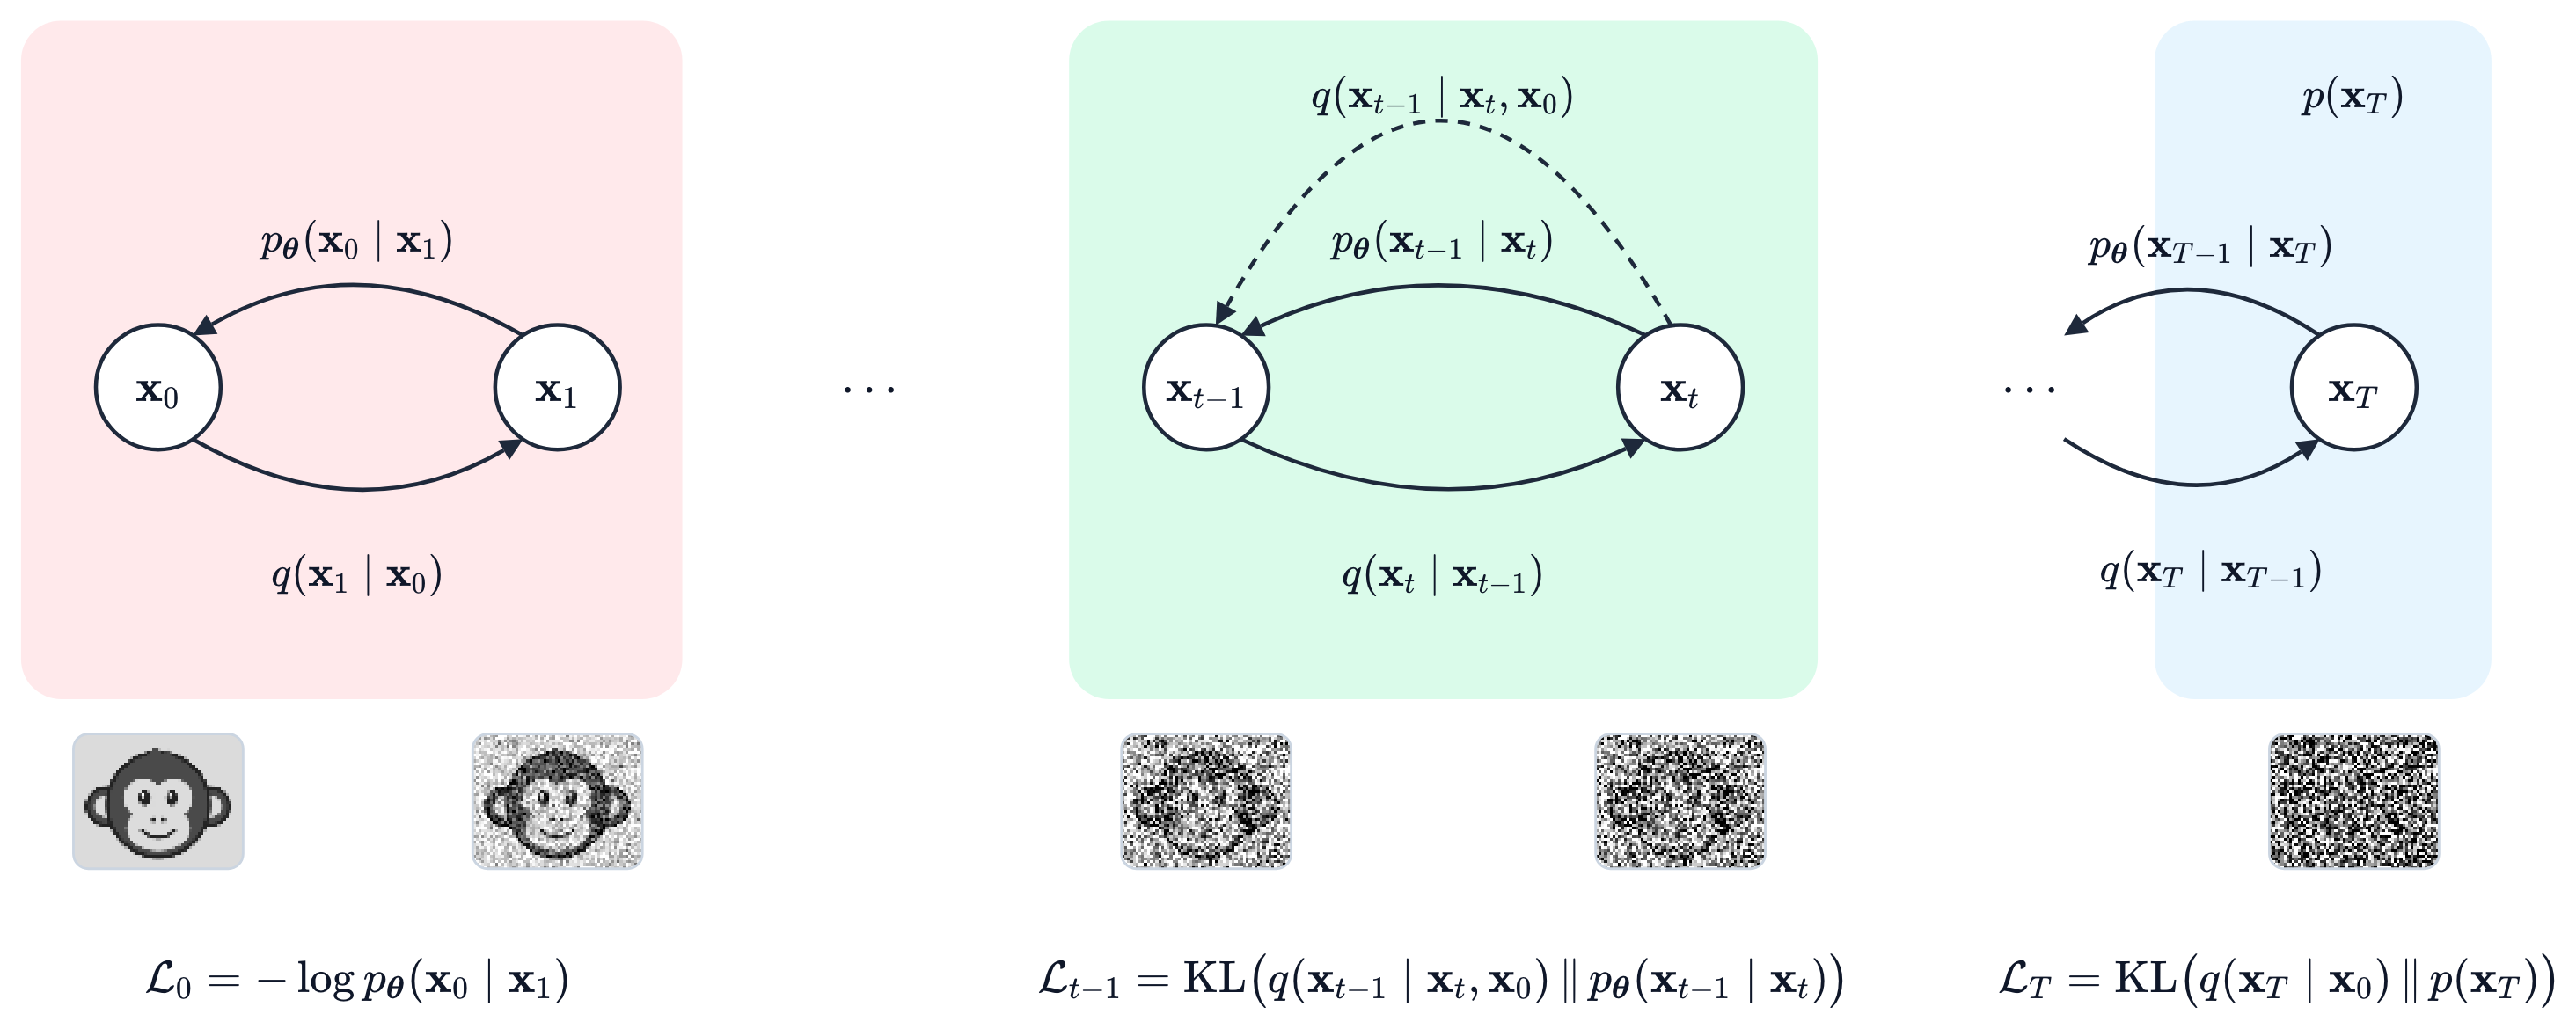

</div>

При фиксированном расписании член с prior не зависит от параметров нейросети. 

При одинаковых дисперсиях:

$$D_{\mathrm{KL}}\big(\mathcal N(\tilde{\boldsymbol\mu}_t,\sigma_t^2\mathbf I)\Vert\mathcal N(\boldsymbol\mu_{\boldsymbol\theta},\sigma_t^2\mathbf I)\big)
=\frac{\|\tilde{\boldsymbol\mu}_t-\boldsymbol\mu_{\boldsymbol\theta}\|^2}{2\sigma_t^2}.$$

<div style="width: 600px; max-width: 100%;">

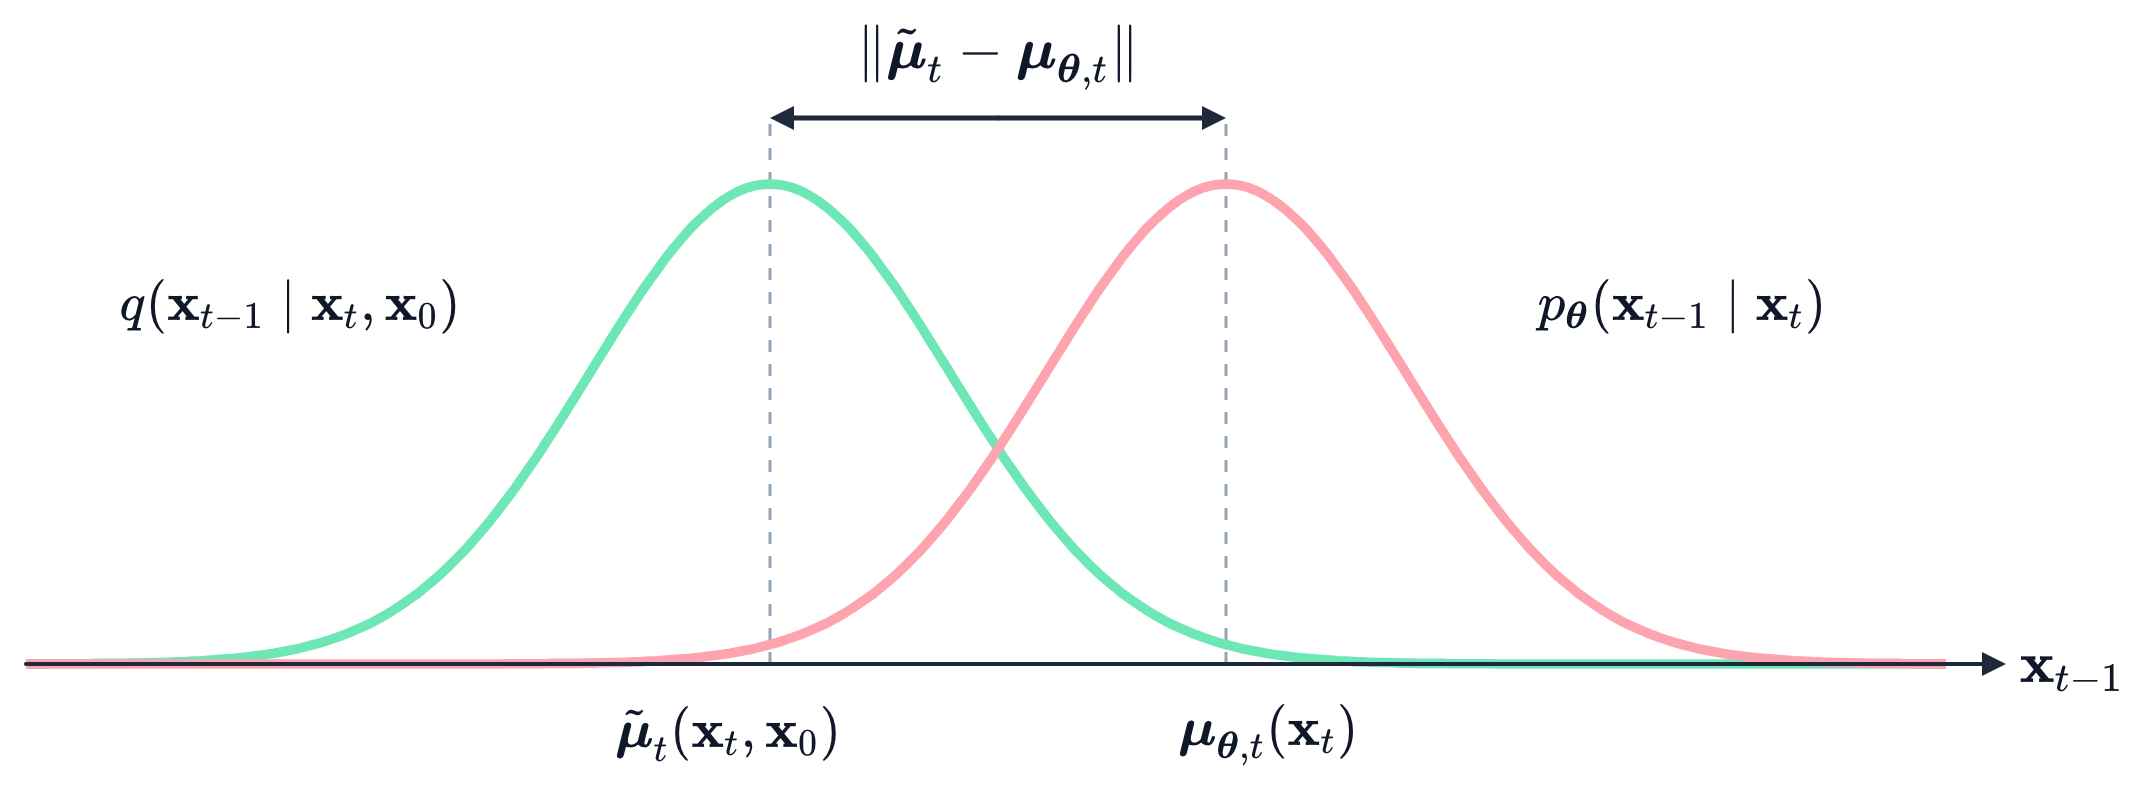

</div>

При одинаковой фиксированной дисперсии KL между двумя гауссианами пропорциональна квадрату расстояния между их средними.

Теперь выберем удобную параметризацию среднего через предсказание шума.

#### Предсказание шума

Из формулы прямого процесса выразим исходный объект:

$$\mathbf{x}_0=\frac{\mathbf{x}_t-\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon}{\sqrt{\bar\alpha_t}}.$$

Подстановка в $\tilde{\boldsymbol\mu}_t$ даёт среднее обратного перехода через шум. Нейросеть будет предсказывать этот шум:

<div style="background-color:#f5f7fa; border:1px solid #d0d7de; border-radius:6px; padding:15px; margin:10px 0; text-align:center;">

$$\boldsymbol\mu_{\boldsymbol\theta}(\mathbf{x}_t,t)=\frac{1}{\sqrt{\alpha_t}}
\left(\mathbf{x}_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\boldsymbol\epsilon_{\boldsymbol\theta}(\mathbf{x}_t,t)\right).$$

</div>

- Сеть получает $\mathbf{x}_t$ и $t$, а возвращает $\boldsymbol\epsilon_{\boldsymbol\theta}$.
- Это не истинный шум для каждого возможного объекта: оптимальный MSE-предсказатель оценивает условное среднее шума при данном зашумлённом входе.

#### Функция потерь DDPM

После репараметризации члены KL при $t\ge2$ содержат веса перед ошибкой шума:

$$\frac{\beta_t^2}{2\sigma_t^2\alpha_t(1-\bar\alpha_t)}
\|\boldsymbol\epsilon-\boldsymbol\epsilon_{\boldsymbol\theta}(\mathbf{x}_t,t)\|^2.$$

В DDPM используется упрощённая цель без этих весов:

<div style="background-color:#f5f7fa; border:1px solid #d0d7de; border-radius:6px; padding:15px; margin:10px 0; text-align:center;">

$$\mathcal L_{\mathrm{simple}}=
\mathbb E_{\mathbf{x}_0,\,t,\,\boldsymbol\epsilon}
\left[\|\boldsymbol\epsilon-\boldsymbol\epsilon_{\boldsymbol\theta}
\left(\sqrt{\bar\alpha_t}\,\mathbf{x}_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon,t\right)\|^2\right],$$

$$t\sim U\{1,\ldots,T\},\qquad\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,\mathbf I).$$

</div>

**Это изменение относительных весов, а не точное вычисление исходной ELBO.** 

В `F.mse_loss` усредняем ошибку по батчу и координатам. 

На каждом шаге обучения:

1. Семплируем батч чистых объектов $\mathbf{x}_0$.
2. Для каждого объекта независимо выбираем $t$ и $\boldsymbol\epsilon$.
3. Получаем $\mathbf{x}_t$ напрямую из $\mathbf{x}_0$.
4. Предсказываем шум и минимизируем MSE относительно **того же шума**, которым зашумляли вход.

<div style="background-color:#eefbf0; border-left:4px solid #22a55e; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Что важно запомнить про обучение DDPM:**


- На обучении известен $x_0$, поэтому мы сами создаём зашумлённые входы и targets.
- Одна нейросеть предсказывает шум для всех времён, получая $t$ как условие.
- По предсказанному шуму вычисляем среднее обратного перехода.
- Простая MSE меняет веса вариационной цели. Её значение само по себе не является оценкой качества сгенерированного распределения.


</div>


### MNIST и архитектура U-Net

Для MNIST используем компактную U-Net на основе DDPM: `ch=64`, `ch_mult=(1,2,2)`, `num_res_blocks=1`, `attn_resolutions=(14,)`, `dropout=0.1`.

- Сохраняем блоки авторской архитектуры, уменьшая число каналов и residual-блоков.
- Уровни разрешения U-Net: $28\to14\to7$ и обратно.

[Архитектура авторов](https://github.com/hojonathanho/diffusion/blob/master/diffusion_tf/models/unet.py).

#### MNIST

MNIST содержит одноканальные изображения цифр от 0 до 9. В тренировочной части 60 000 изображений, в тестовой 10 000.

Переведём пиксели из $[0,1]$ в $[-1,1]$.

Генерация **условная**: U-Net получает изображение, время и метку цифры $y\in\{0,\ldots,9\}$.

In [33]:
from pathlib import Path
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
from torchvision.datasets import MNIST
from torchvision.utils import make_grid

DATA_DIR = Path("data")
CHECKPOINT_DIR = Path("checkpoints")
best_checkpoint_path = CHECKPOINT_DIR / "best_model.pt"


In [34]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
mnist_dataset = MNIST(root=str(DATA_DIR), train=True, transform=mnist_transform, download=True)
mnist_train_dataset, mnist_val_dataset = random_split(
    mnist_dataset, [55000, 5000]
)
mnist_val_loader = DataLoader(mnist_val_dataset, batch_size=64, shuffle=False)
print(f"Train: {len(mnist_train_dataset)}, Validation: {len(mnist_val_dataset)}")


Train: 55000, Validation: 5000


Images: (64, 1, 28, 28), labels: (64,)
Pixel range: [-1.0, 1.0]


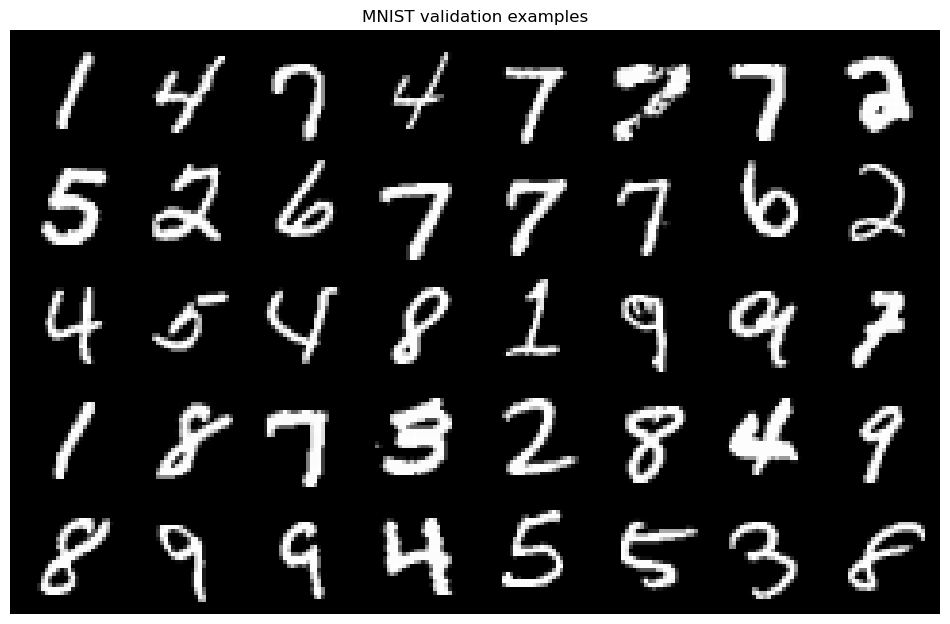

In [35]:
def show_images(images, nrow=8, title="", normalized=True):
    images = images.detach().cpu()
    if normalized:
        images = (images + 1) / 2
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    rows = math.ceil(len(images) / nrow)
    plt.figure(figsize=(min(nrow, len(images)) * 1.2, rows * 1.2 + 0.5))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

mnist_examples, mnist_labels = next(iter(mnist_val_loader))
print(f"Images: {tuple(mnist_examples.shape)}, labels: {tuple(mnist_labels.shape)}")
print(f"Pixel range: [{mnist_examples.min().item():.1f}, {mnist_examples.max().item():.1f}]")
show_images(mnist_examples[:40], nrow=8, title="MNIST validation examples")


#### Идея U-Net

**U-Net** — свёрточная сеть с encoder, decoder и связями между ними:

- **Encoder** уменьшает разрешение и собирает контекст: какие части изображения связаны между собой.
- **Bottleneck** обрабатывает признаки на самом низком уровне.
- **Decoder** увеличивает разрешение и через **skip connections** получает признаки encoder того же размера, чтобы восстанавливать мелкие детали.

- В DDPM на вход подаём зашумлённое изображение $x_t$, а на выходе получаем оценку шума $\epsilon_\theta(x_t,t,y)$ того же размера.
- Сумма embeddings времени $t$ и класса $y$ задаёт условие и добавляется в residual-блоки обеих ветвей и bottleneck.

<div style="width: 760px; max-width: 100%;">

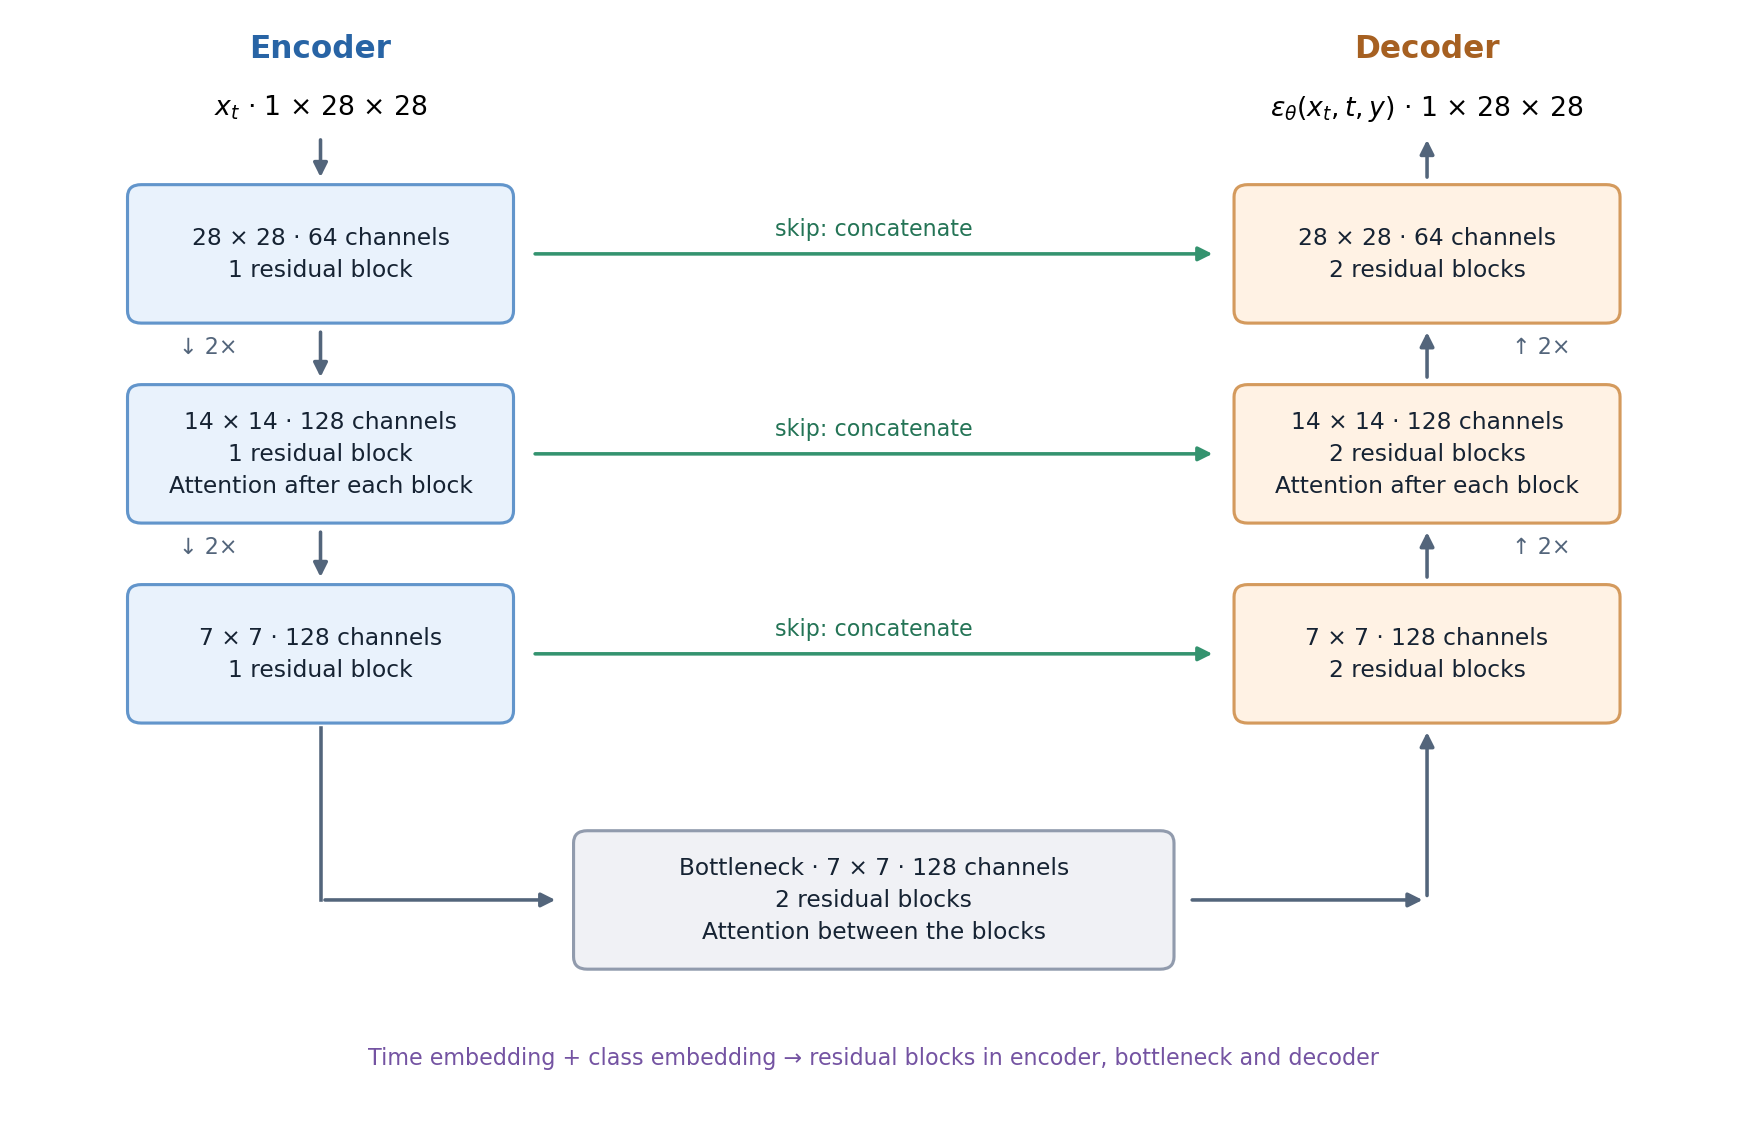

</div>

#### U-Net и skip connections

- В энкодере на каждом разрешении стоит **один residual-блок**, в декодере — **два**.
- Сохраняем выход входной свёртки, каждого блока энкодера и каждого downsample.
- Все 6 сохранённых тензоров декодер последовательно использует в skip connections.

Внутри residual-блока признаки складываем. Перед каждым блоком декодера конкатенируем текущие признаки с очередным сохранённым тензором энкодера.

- На входе и выходе сети свёртки $3\times3$.
- Downsample сохраняет число каналов: добавляет по одному нулевому столбцу справа и строке снизу, затем применяет свёртку $3\times3$ с шагом 2.
- Так разрешение уменьшается вдвое: $28 \to 14 \to 7$.
- Upsample увеличивает разрешение методом nearest neighbor, затем применяет свёртку $3\times3$ без изменения числа каналов.


<div style="width: 760px; max-width: 100%;">

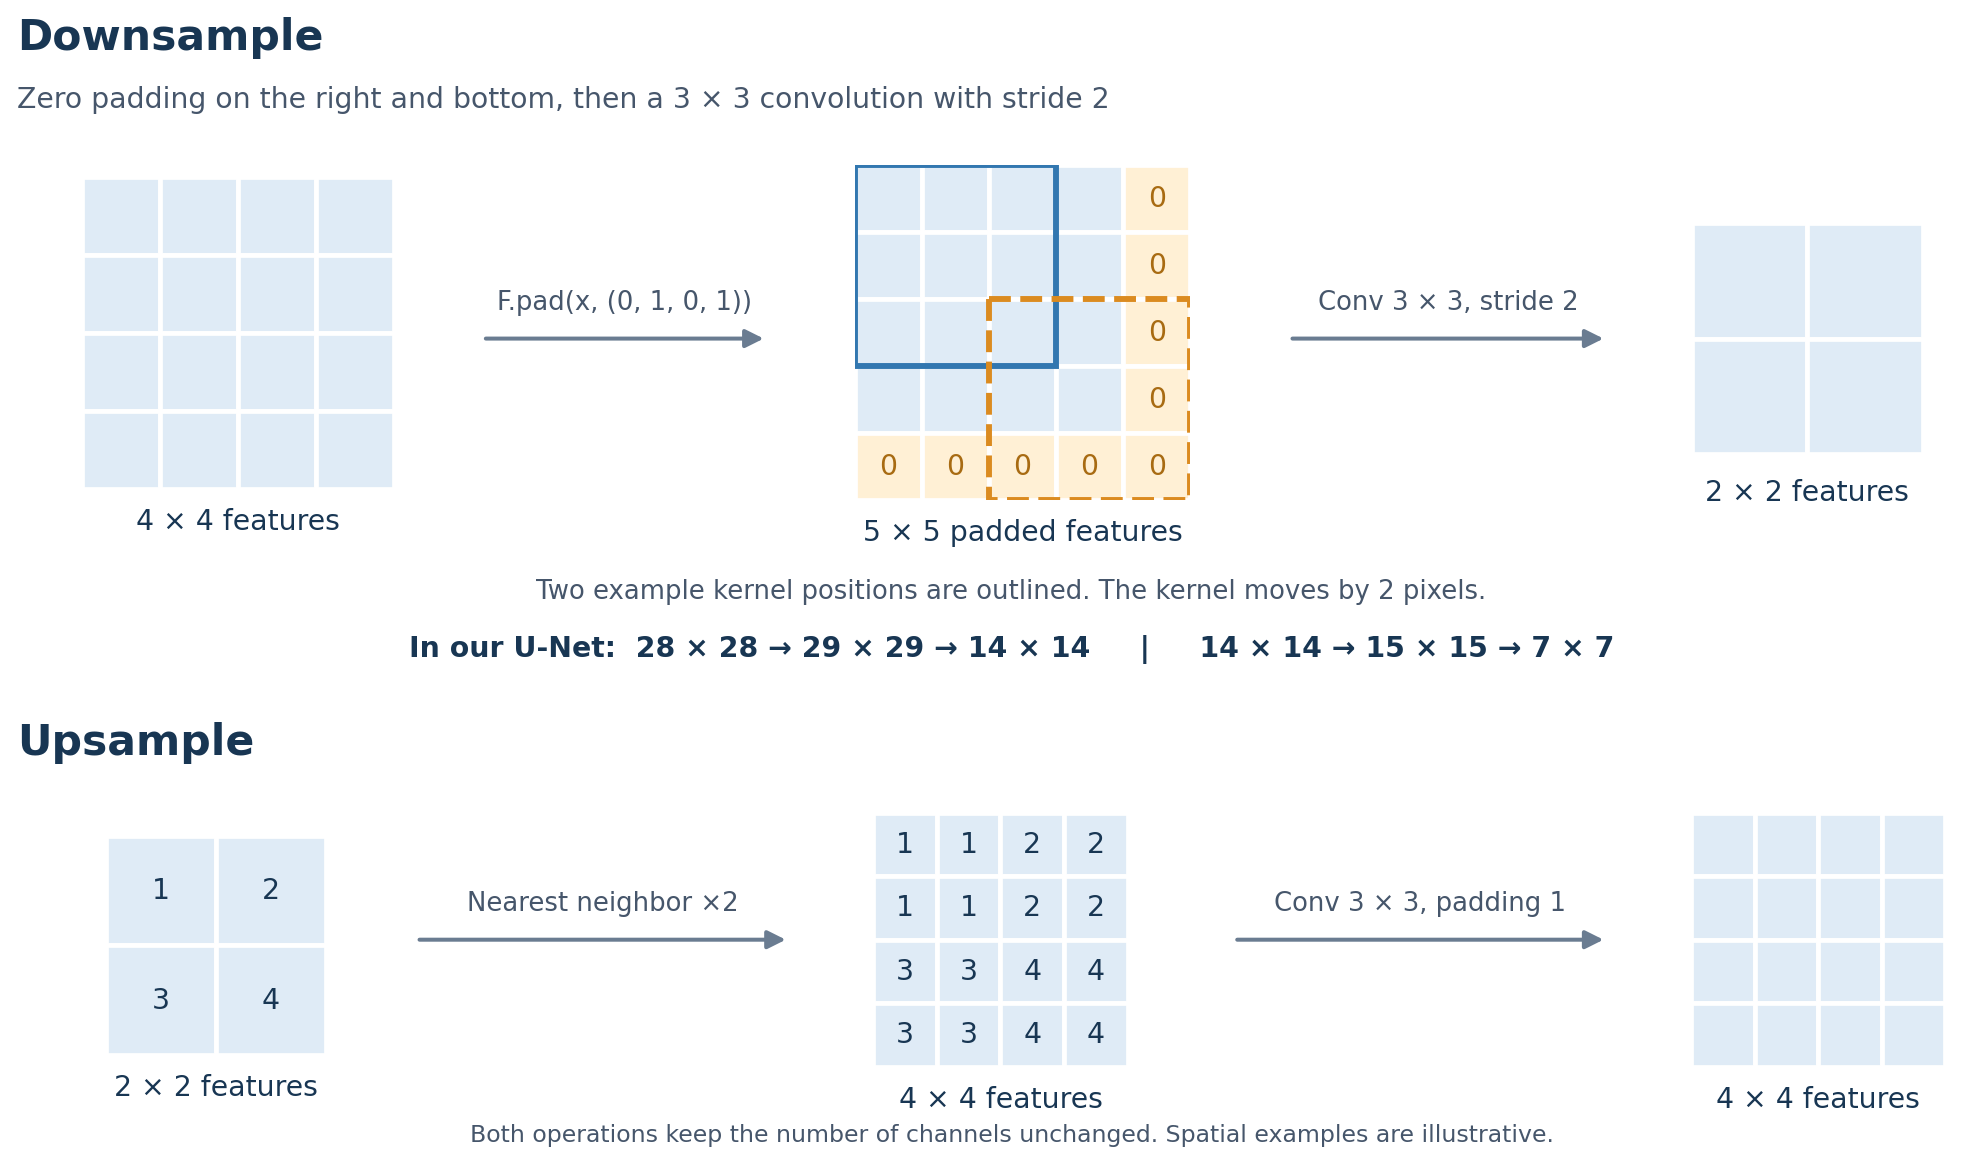

</div>

#### Time Embedding и residual block

Время $t$ сообщает сети уровень зашумления. Преобразуем его в вектор с помощью синусов и косинусов разных частот:

$$\mathbf e_t=\left[
\sin\left(t\exp\left(-\frac{k\log10000}{d/2-1}\right)\right),\;
\cos\left(t\exp\left(-\frac{k\log10000}{d/2-1}\right)\right)
\right]_{k=0}^{d/2-1}.$$

- В `TimeEmbedding` используем 32 фиксированные частоты от $1$ до $10^{-4}$. Объединяем 32 синуса и 32 косинуса в вектор $(B,64)$.
- Обучаемая проекция `Linear(64,256) → SiLU → Linear(256,256)` даёт $(B,256)$.
- На вход подаём $t\in\{1,\ldots,T\}$ без сдвига; $B$ — размер батча.

<div style="width: 760px; max-width: 100%;">

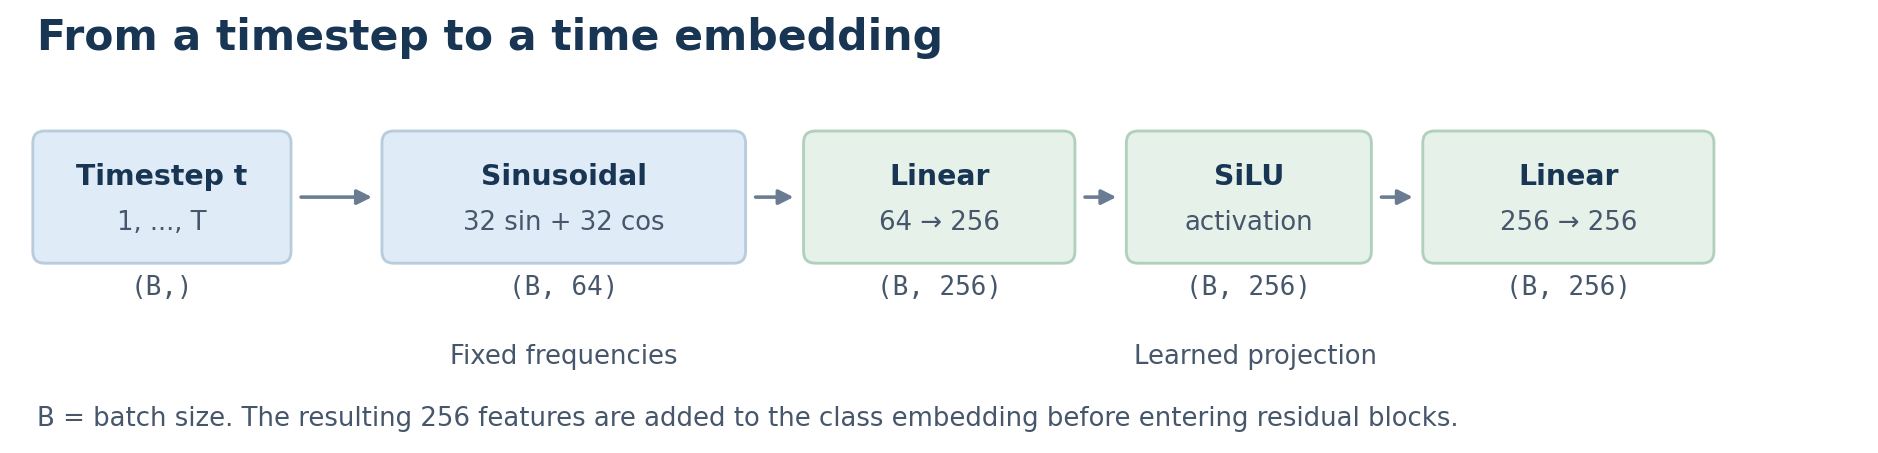

</div>

Прибавляем обучаемый эмбеддинг класса той же размерности:

$$e(t,y)=\operatorname{TimeMLP}(t)+\operatorname{ClassEmbedding}(y).$$

- Функция потерь остаётся MSE предсказанного шума, но теперь сеть учит $\epsilon_\theta(x_t,t,y)$.

- Каждый residual-блок устроен так: GroupNorm, SiLU, свёртка, добавление проекции времени, GroupNorm, SiLU, dropout, свёртка и residual-сложение.
- В GroupNorm используем 32 группы.

- Последние свёртки residual-ветвей, attention и выхода инициализируем нулями. Сеть сначала предсказывает ноль; residual-блоки возвращают shortcut, а attention — свой вход.


<div style="width: 760px; max-width: 100%;">

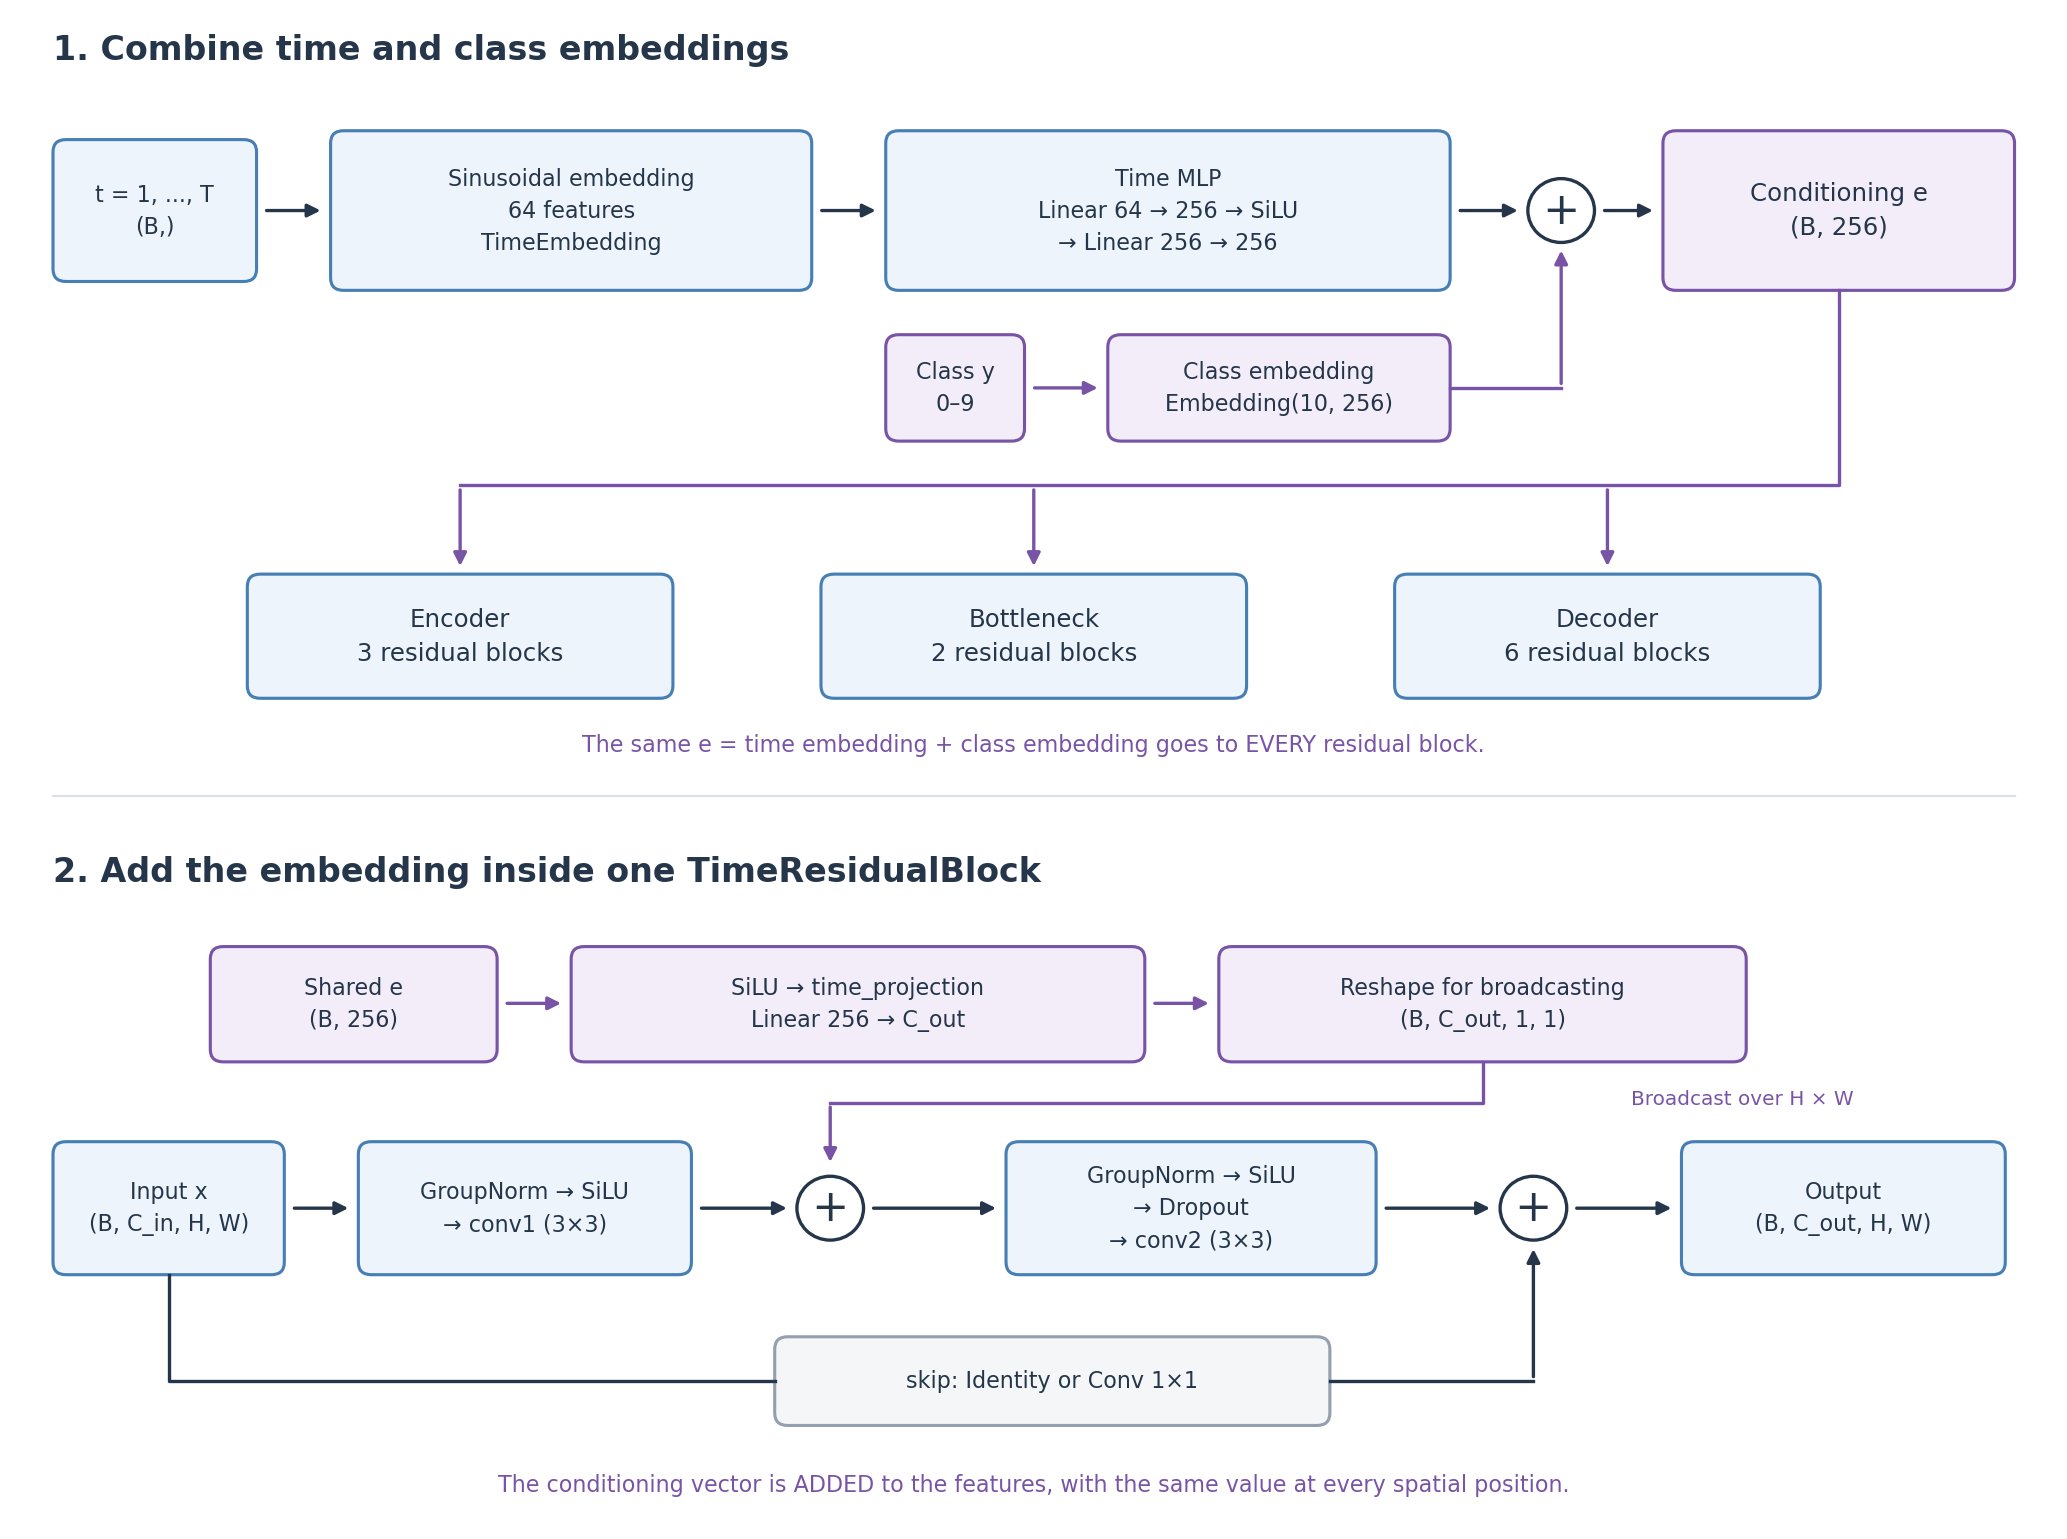

</div>

**Подача условия в residual-блоки:**

- Общий вектор $e(t,y)$ вычисляем один раз и передаём во все 11 residual-блоков.
- Каждый блок собственной проекцией переводит 256 признаков в число своих выходных каналов.
- После первой свёртки прибавляем проекцию ко всем пространственным позициям:

```python
h = h + self.time_projection(F.silu(time_embedding))[:, :, None, None]
```

Например: $(B,256)\to(B,128)\to(B,128,1,1)$ прибавляем к $(B,128,14,14)$. Размер карты признаков сохраняется.


In [36]:
class TimeEmbedding(nn.Module):
    def __init__(self, embedding_dim=64):
        super().__init__()
        half_dim = embedding_dim // 2
        log_spacing = math.log(10000) / (half_dim - 1)
        frequencies = torch.exp(-log_spacing * torch.arange(half_dim, dtype=torch.float32))  # 32 frequencies from 1 down to 1e-4.
        self.register_buffer("frequencies", frequencies)

    def forward(self, timesteps):
        phases = timesteps.float()[:, None] * self.frequencies[None, :]  # Shape: (B, embedding_dim // 2).
        embedding = torch.cat([phases.sin(), phases.cos()], dim=1)
        return embedding


Time embedding shape: (4, 64)


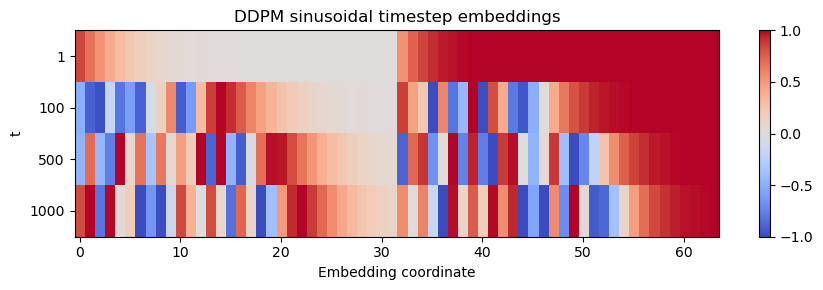

In [37]:
time_embedding = TimeEmbedding(embedding_dim=64).to(device)
test_t = torch.tensor([1, 100, 500, 1000], device=device)
with torch.no_grad():
    embedded_times = time_embedding(test_t)
print(f"Time embedding shape: {tuple(embedded_times.shape)}")
plt.figure(figsize=(9, 3))
plt.imshow(embedded_times.cpu().numpy(), aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.yticks(range(len(test_t)), test_t.cpu().numpy())
plt.xlabel("Embedding coordinate")
plt.ylabel("t")
plt.title("DDPM sinusoidal timestep embeddings")
plt.colorbar()
plt.tight_layout()
plt.show()

In [39]:
class TimeResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, in_channels, eps=1e-6)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(32, out_channels, eps=1e-6)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        nn.init.zeros_(self.conv2.weight)  # Initialize the residual branch at zero.
        nn.init.zeros_(self.conv2.bias)
        self.skip = (  # 1x1 conv matches channels when in_channels != out_channels.
            nn.Identity() if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1, padding=0)
        )

    def forward(self, x, time_embedding):
        """Process features and add the projected time-and-class conditioning."""
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(F.silu(time_embedding))[:, :, None, None]  # Broadcast conditioning over H and W.
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return self.skip(x) + h  # Add the residual shortcut.


In [40]:
class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=0)

    def forward(self, x):
        return self.conv(F.pad(x, (0, 1, 0, 1)))  # Pad right and bottom before stride-2 convolution.

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


#### Self-Attention

Один attention-блок связывает все пространственные позиции изображения. После GroupNorm получаем $Q$, $K$ и $V$ с помощью независимых проекций $1\times1$. Для $N=H\cdot W$ позиций $Q,K,V\in\mathbb R^{N\times C}$: каждая строка содержит признаки одной позиции.

$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt C}\right),\qquad
\mathbf y=\mathbf x+\operatorname{Proj}(AV).$$

- Свёртки возвращают тензоры $(B,C,H,W)$, поэтому в коде переводим их в формат $(B,N,C)$, а после attention возвращаем обратно.

- **batch matrix multiplication** отдельно умножает соответствующие матрицы каждого изображения в батче.
- Это single-head attention, как в официальном `attn_block`.
- Его применяем после каждого residual-блока на разрешении $14\times14$ и один раз между двумя residual-блоками bottleneck на $7\times7$.

In [41]:
class AttentionBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.GroupNorm(32, channels, eps=1e-6)
        self.q = nn.Conv2d(channels, channels, 1, padding=0)
        self.k = nn.Conv2d(channels, channels, 1, padding=0)
        self.v = nn.Conv2d(channels, channels, 1, padding=0)
        self.proj_out = nn.Conv2d(channels, channels, 1, padding=0)
        nn.init.zeros_(self.proj_out.weight)  # Attention starts as the identity: y = x.
        nn.init.zeros_(self.proj_out.bias)

    def forward(self, x):
        """Apply single-head self-attention across all spatial positions."""
        batch, channels, height, width = x.shape
        h = self.norm(x)

        q = self.q(h).reshape(batch, channels, height * width).transpose(1, 2)  # (B, N, C), N = H*W positions.
        k = self.k(h).reshape(batch, channels, height * width).transpose(1, 2)
        v = self.v(h).reshape(batch, channels, height * width).transpose(1, 2)

        weights = torch.bmm(q, k.transpose(1, 2)) * channels ** -0.5  # bmm = batch matrix multiplication; scores: (B, N, N).
        weights = weights.softmax(dim=-1)  # Normalize over key positions.

        h = torch.bmm(weights, v)  # Weighted sum of values for each query: (B, N, C).
        h = h.transpose(1, 2).reshape(batch, channels, height, width)  # Back to (B, C, H, W).
        return x + self.proj_out(h)


In [42]:
class DDPMUNet(nn.Module):
    def __init__(self, image_size=28, image_channels=1, base_channels=64,
                 channel_mult=(1, 2, 2), num_res_blocks=1,
                 attn_resolutions=(14,), dropout=0.1, num_classes=10):
        super().__init__()

        self.image_size = image_size
        self.image_channels = image_channels
        self.num_levels = len(channel_mult)
        self.num_classes = num_classes
        time_dim = 4 * base_channels  # Size of the shared conditioning vector, as in DDPM.

        # Time and class conditioning.
        self.time_mlp = nn.Sequential(
            TimeEmbedding(base_channels),
            nn.Linear(base_channels, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.class_embedding = nn.Embedding(num_classes, time_dim)
        self.input_conv = nn.Conv2d(image_channels, base_channels, 3, padding=1)

        # Encoder: save channel counts for the decoder skip connections.
        self.down_levels, channels, skip_channels = self._build_encoder(
            base_channels, channel_mult, num_res_blocks,
            attn_resolutions, time_dim, dropout,
        )

        # Bottleneck: residual block, attention, residual block.
        self.middle1 = TimeResidualBlock(channels, channels, time_dim, dropout)
        self.middle_attention = AttentionBlock(channels)
        self.middle2 = TimeResidualBlock(channels, channels, time_dim, dropout)

        # Decoder and output projection.
        self.up_levels, channels = self._build_decoder(
            channels, skip_channels, base_channels, channel_mult,
            num_res_blocks, attn_resolutions, time_dim, dropout,
        )
        self.output = nn.Sequential(
            nn.GroupNorm(32, channels, eps=1e-6),
            nn.SiLU(),
            nn.Conv2d(channels, image_channels, 3, padding=1),
        )
        nn.init.zeros_(self.output[-1].weight)  # The network initially predicts zero noise.
        nn.init.zeros_(self.output[-1].bias)

    def _build_encoder(self, base_channels, channel_mult, num_res_blocks,
                       attn_resolutions, time_dim, dropout):
        """Build encoder levels and record the channels of each saved tensor."""
        levels = nn.ModuleList()
        channels = base_channels
        skip_channels = [channels]
        resolution = self.image_size  # Track spatial size to decide where attention is used.

        for level, multiplier in enumerate(channel_mult):
            out_channels = base_channels * multiplier
            blocks = nn.ModuleList()
            attentions = nn.ModuleList()

            for _ in range(num_res_blocks):
                blocks.append(TimeResidualBlock(channels, out_channels, time_dim, dropout))
                channels = out_channels
                attention = AttentionBlock(channels) if resolution in attn_resolutions else nn.Identity()
                attentions.append(attention)
                skip_channels.append(channels)

            has_downsample = level < self.num_levels - 1
            levels.append(nn.ModuleDict({
                "blocks": blocks,
                "attentions": attentions,
                "downsample": Downsample(channels) if has_downsample else nn.Identity(),
            }))
            if has_downsample:
                skip_channels.append(channels)
                resolution //= 2

        return levels, channels, skip_channels

    def _build_decoder(self, channels, skip_channels, base_channels, channel_mult,
                       num_res_blocks, attn_resolutions, time_dim, dropout):
        """Build decoder levels, consuming skip channels in reverse order."""
        levels = nn.ModuleDict()
        resolution = self.image_size // (2 ** (self.num_levels - 1))

        for level in reversed(range(self.num_levels)):
            out_channels = base_channels * channel_mult[level]
            blocks = nn.ModuleList()
            attentions = nn.ModuleList()

            for _ in range(num_res_blocks + 1):  # One extra block consumes the downsample skip.
                in_channels = channels + skip_channels.pop()  # Skips are used in reverse order.
                blocks.append(TimeResidualBlock(in_channels, out_channels, time_dim, dropout))
                channels = out_channels
                attention = AttentionBlock(channels) if resolution in attn_resolutions else nn.Identity()
                attentions.append(attention)

            levels[str(level)] = nn.ModuleDict({
                "blocks": blocks,
                "attentions": attentions,
                "upsample": Upsample(channels) if level > 0 else nn.Identity(),
            })
            if level > 0:
                resolution *= 2

        assert not skip_channels
        return levels, channels

    def forward(self, x_t, t, labels):
        """Predict noise from an image, timestep and class label."""

        embedding = self.time_mlp(t) + self.class_embedding(labels)
        h = self.input_conv(x_t)
        skips = [h]  # The input convolution output is the first saved skip.

        # Encoder: retain features before each reduction in resolution.
        # Attention is nn.Identity at resolutions without self-attention.
        for level, modules in enumerate(self.down_levels):
            for block, attention in zip(modules["blocks"], modules["attentions"]):
                h = block(h, embedding)
                h = attention(h)
                skips.append(h)
            if level < self.num_levels - 1:
                h = modules["downsample"](h)
                skips.append(h)

        # Bottleneck.
        h = self.middle1(h, embedding)
        h = self.middle_attention(h)
        h = self.middle2(h, embedding)

        # Decoder: concatenate the matching encoder features before each block.
        for level in reversed(range(self.num_levels)):
            modules = self.up_levels[str(level)]
            for block, attention in zip(modules["blocks"], modules["attentions"]):
                h = torch.cat([h, skips.pop()], dim=1)
                h = block(h, embedding)
                h = attention(h)
            if level > 0:
                h = modules["upsample"](h)
        assert not skips

        noise_pred = self.output(h)
        return noise_pred


In [43]:
mnist_model = DDPMUNet(
    image_size=28, image_channels=1, num_classes=10,
    base_channels=64, channel_mult=(1, 2, 2),
    num_res_blocks=1, attn_resolutions=(14,), dropout=0.1,
).to(device)

print(f"Parameters: {sum(p.numel() for p in mnist_model.parameters()):,}")


Parameters: 4,437,953


<div style="background-color:#eefbf0; border-left:4px solid #22a55e; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Что важно запомнить про U-Net:**

- Предсказываем шум каждого пикселя $28\times28$.
- В residual-блоках есть time embedding и dropout, на $14\times14$ и в bottleneck есть self-attention.
- Сеть использует всё зашумлённое изображение при предсказании шума.

</div>


#### Прямое зашумление изображений

- Соберём расписание и формулы прямого процесса в `ImageDiffusion`.
- Здесь же храним коэффициенты обратного перехода и вычисляем его среднее в `p_mean`; они понадобятся при сэмплировании.
- Функция `extract` добавляет оси для broadcasting коэффициентов по пикселям.
- Используем $T=1000$ и линейное расписание от $10^{-4}$ до $0.02$.


In [44]:
class ImageDiffusion(nn.Module):
    def __init__(self, T=1000):
        super().__init__()
        self.T = T

        # Forward noise schedule.
        betas, alphas, alpha_bars = make_schedule(T)

        # Reverse variance and posterior-mean coefficients.
        # posterior mean: mu = coef_x0 * x_0 + coef_xt * x_t; at t = 1 the variance is 0.
        posterior_variance = torch.zeros_like(betas)
        posterior_variance[1:] = betas[1:] * (1 - alpha_bars[:-1]) / (1 - alpha_bars[1:])
        coef_x0 = torch.zeros_like(betas)
        coef_xt = torch.zeros_like(betas)
        coef_x0[1:] = alpha_bars[:-1].sqrt() * betas[1:] / (1 - alpha_bars[1:])
        coef_xt[1:] = alphas[1:].sqrt() * (1 - alpha_bars[:-1]) / (1 - alpha_bars[1:])

        self.register_buffer("betas", betas)  # beta_t: forward noise variance.
        self.register_buffer("alphas", alphas)  # alpha_t = 1 - beta_t.
        self.register_buffer("alpha_bars", alpha_bars)  # alpha_bar_t = product of alpha_1 through alpha_t.
        self.register_buffer("posterior_variance", posterior_variance)  # beta_tilde_t: beta_t * (1 - alpha_bar_{t-1}) / (1 - alpha_bar_t).
        self.register_buffer("posterior_coef_x0", coef_x0)  # Coefficient of x_0: sqrt(alpha_bar_{t-1}) * beta_t / (1 - alpha_bar_t).
        self.register_buffer("posterior_coef_xt", coef_xt)  # Coefficient of x_t: sqrt(alpha_t) * (1 - alpha_bar_{t-1}) / (1 - alpha_bar_t).


    def q_sample(self, x_0, t, noise=None):
        return q_sample(x_0, t, self.alpha_bars, noise)

    def predict_x0(self, x_t, t, noise_pred):
        """Invert q_sample: estimate x_0 from x_t and the predicted noise."""
        bar = extract(self.alpha_bars, t, x_t)
        return (x_t - (1 - bar).sqrt() * noise_pred) / bar.sqrt()

    def p_mean(self, x_t, t, noise_pred):
        """Compute the reverse mean using a clipped clean-image estimate."""
        x0_pred = self.predict_x0(x_t, t, noise_pred).clamp(-1, 1)
        return (extract(self.posterior_coef_x0, t, x_t) * x0_pred
                + extract(self.posterior_coef_xt, t, x_t) * x_t)


In [45]:
mnist_diffusion = ImageDiffusion(T=1000).to(device)
print(f"T={mnist_diffusion.T}, alpha_bar_T={mnist_diffusion.alpha_bars[-1].item():.6f}")


T=1000, alpha_bar_T=0.000040


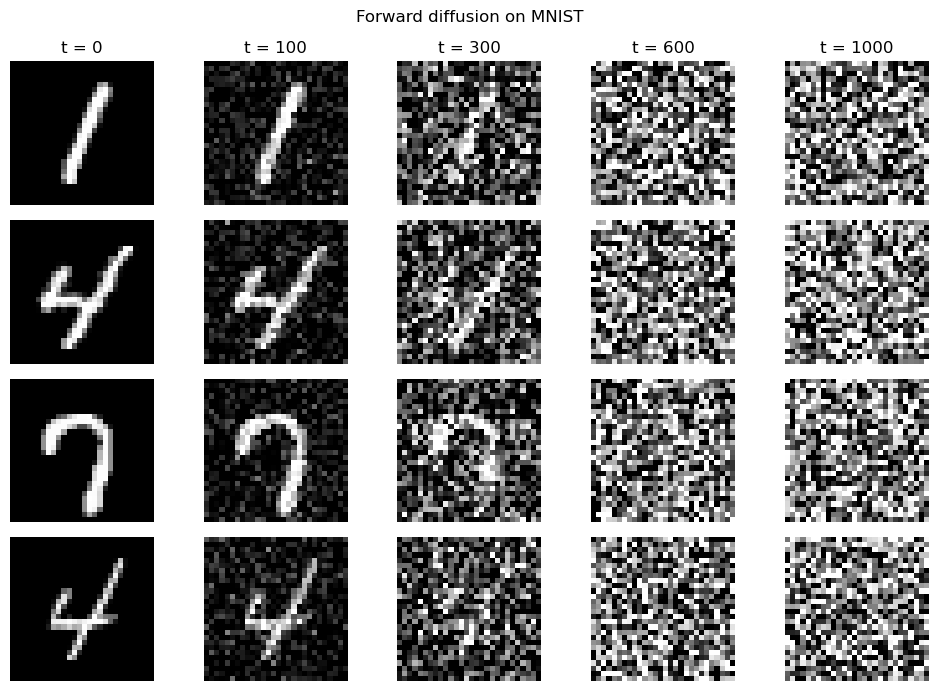

In [46]:
visual_images = mnist_examples[:4].to(device)
visual_times = [0, mnist_diffusion.T // 10, 3 * mnist_diffusion.T // 10,
                6 * mnist_diffusion.T // 10, mnist_diffusion.T]
fig, axes = plt.subplots(len(visual_images), len(visual_times), figsize=(10, 7))
for column, time in enumerate(visual_times):
    t = torch.full((len(visual_images),), time, dtype=torch.long, device=device)
    noise = torch.randn_like(visual_images)
    noisy = mnist_diffusion.q_sample(visual_images, t, noise).cpu()
    for row in range(len(visual_images)):
        axes[row, column].imshow((noisy[row, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(f"t = {time}")
plt.suptitle("Forward diffusion on MNIST")
plt.tight_layout()
plt.show()


### Training and Validation Loop

In [47]:
def diffusion_loss(model, diffusion, x_0, labels):
    """Compute class-conditional noise MSE with fresh timesteps and noise."""
    t = torch.randint(1, diffusion.T + 1, (len(x_0),), device=x_0.device)  # Sample one timestep per image.
    noise = torch.randn_like(x_0)
    x_t = diffusion.q_sample(x_0, t, noise)
    noise_pred = model(x_t, t, labels)
    return F.mse_loss(noise_pred, noise)  # The added noise is the training target.


In [48]:
def train_one_epoch(model, diffusion, loader, optimizer, device):
    """Update weights on the full training set and return the mean noise MSE."""
    model.train()
    total_loss, total_images = 0.0, 0
    progress = tqdm(loader, desc="Train", leave=False)
    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = diffusion_loss(model, diffusion, images, labels)  # Sample fresh corruption for this batch.
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)  # Weight the last, smaller batch correctly.
        total_images += len(images)
        progress.set_postfix(loss=f"{total_loss / total_images:.4f}")
    return total_loss / total_images

@torch.no_grad()
def validate_one_epoch(model, diffusion, loader, device):
    """Evaluate all validation images with freshly sampled timesteps and noise."""
    model.eval()
    total_loss, total_images = 0.0, 0

    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        loss = diffusion_loss(model, diffusion, images, labels)
        total_loss += loss.item() * len(images)
        total_images += len(images)

    return total_loss / total_images


#### Визуализация и сохранение модели

- После каждой эпохи показываем графики потерь и сгенерированные цифры.
- Сохраняем только веса с минимальным validation loss в `best_model.pt`, перезаписывая тот же файл.


#### Ancestral sampling

Наш sampler реализует **ancestral sampling**: сэмплируем переменные по порядку зависимостей в генеративной модели. Для условной DDPM:

$$p_\theta(x_{0:T}\mid y)=p(x_T)\prod_{t=1}^{T}p_\theta(x_{t-1}\mid x_t,y).$$

- Сначала выбираем $x_T\sim\mathcal N(0,I)$, затем последовательно получаем $x_{T-1},\ldots,x_0$.
- На каждом шаге новое состояние зависит от уже полученного $x_t$ и фиксированного класса $y$.
- В нашей реализации:

$$x_{t-1}=\mu_\theta(x_t,t,y)+\sqrt{\tilde\beta_t}\,z_t,\qquad z_t\sim\mathcal N(0,I),$$

где при $t>1$ шум $z_t$ сэмплируем заново, а последний переход $t=1$ выполняем без добавления шума. Функция `p_sample` реализует один переход, `sample` — всю цепь.

#### Один обратный шаг

Фиксируем дисперсию обратного перехода равной $\tilde\beta_t$. Тогда при $t>1$:

<div style="background-color:#f5f7fa; border:1px solid #d0d7de; border-radius:6px; padding:15px; margin:10px 0; text-align:center;">

$$\mathbf{x}_{t-1}=\frac{1}{\sqrt{\alpha_t}}
\left(\mathbf{x}_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\boldsymbol\epsilon_{\boldsymbol\theta}(\mathbf{x}_t,t,y)\right)
+\sqrt{\tilde\beta_t}\,\mathbf z,\qquad \mathbf z\sim\mathcal N(\mathbf0,\mathbf I).$$

</div>

В `p_mean` вычисляем $\hat{\mathbf{x}}_0$, ограничиваем его диапазоном $[-1,1]$ и подставляем в формулу posterior mean.

На последнем шаге $t=1$ возвращаем среднее без дополнительного шума.


In [49]:
@torch.no_grad()
def p_sample(model, diffusion, x_t, t, labels):
    """Take one ancestral DDPM step conditioned on class; add no noise at t = 1."""
    noise_pred = model(x_t, t, labels)
    mean = diffusion.p_mean(x_t, t, noise_pred)
    variance = extract(diffusion.posterior_variance, t, x_t)  # Use the analytic posterior variance.
    z = torch.randn_like(x_t)
    nonzero_mask = (t > 1).reshape(t.shape[0], *([1] * (x_t.ndim - 1)))  # Explicit: no noise at t = 1 (beta_tilde_1 is already 0).
    return mean + nonzero_mask * variance.sqrt() * z  # x_{t-1} = mu + sqrt(beta_tilde) * z.


In [51]:
@torch.no_grad()
def sample(model, diffusion, labels):
    """Generate images conditioned on the requested class labels."""
    model.eval()
    labels = torch.as_tensor(labels, dtype=torch.long, device=diffusion.betas.device)
    x = torch.randn(
        len(labels), model.image_channels, model.image_size, model.image_size,
        device=diffusion.betas.device,
    )

    for step in tqdm(range(diffusion.T, 0, -1), desc="Sampling", leave=False):
        t = torch.full((len(x),), step, dtype=torch.long, device=x.device)
        x = p_sample(model, diffusion, x, t, labels)

    return x


In [52]:
def plot_losses(history):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train"], label="Train MSE")
    plt.plot(history["epoch"], history["val"], label="Validation MSE")
    plt.xlabel("Epoch")
    plt.ylabel("Noise prediction MSE")
    plt.title("DDPM on MNIST")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


In [53]:
def train_and_validate(model, diffusion, train_loader, val_loader,
                       epochs, lr, checkpoint_path, device):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"epoch": [], "train": [], "val": []}
    best_val = float("inf")
    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}", flush=True)

        # Train, validate and update the loss history.
        train_loss = train_one_epoch(model, diffusion, train_loader, optimizer, device)
        val_loss = validate_one_epoch(model, diffusion, val_loader, device)

        history["epoch"].append(epoch)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        # Overwrite the same file only when validation loss improves.
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), checkpoint_path)

        # Refresh loss curves and preview one sample per class.
        clear_output(wait=True)
        plot_losses(history)
        print(f"Epoch {epoch}/{epochs}: Train={train_loss:.4f}, "
              f"Val={val_loss:.4f}, Best Val={best_val:.4f}", flush=True)

        preview_labels = torch.arange(model.num_classes, device=device)
        preview = sample(model, diffusion, labels=preview_labels)
        show_images(preview, nrow=10, title=f"Requested digits 0–9, epoch {epoch}")


#### Запуск обучения

- Параметры `batch_size`, `epochs` и `lr` задаём ниже.
- После каждой эпохи рисуем train/validation loss и генерируем по одному изображению каждого класса.
- Сохраняем только лучшие веса в `best_model.pt`.

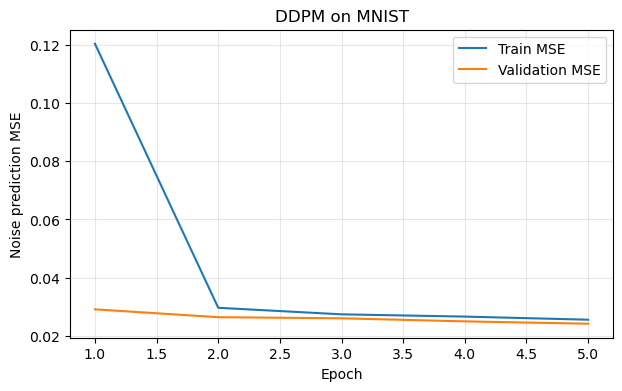

Epoch 5/5: Train=0.0255, Val=0.0241, Best Val=0.0241


Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

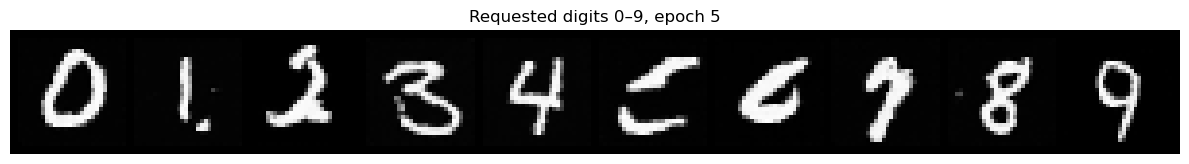

In [54]:
batch_size = 128
epochs = 5
lr = 1e-4

mnist_train_loader = DataLoader(
    mnist_train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)
train_and_validate(
    mnist_model, mnist_diffusion, mnist_train_loader, mnist_val_loader,
    epochs=epochs, lr=lr, checkpoint_path=best_checkpoint_path, device=device,
)


#### Загрузка обученной модели

- Загрузим веса из `best_model.pt` в созданную выше модель с той же архитектурой и расписанием диффузии.
- Если `best_model.pt` уже есть, ячейку запуска обучения можно пропустить после создания модели и расписания. После обучения также загружаем лучшие веса для генерации.


In [55]:
mnist_model.load_state_dict(torch.load(best_checkpoint_path, map_location=device, weights_only=True))
mnist_model.eval()


DDPMUNet(
  (time_mlp): Sequential(
    (0): TimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (class_embedding): Embedding(10, 256)
  (input_conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_levels): ModuleList(
    (0): ModuleDict(
      (blocks): ModuleList(
        (0): TimeResidualBlock(
          (norm1): GroupNorm(32, 64, eps=1e-06, affine=True)
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_projection): Linear(in_features=256, out_features=64, bias=True)
          (norm2): GroupNorm(32, 64, eps=1e-06, affine=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (skip): Identity()
        )
      )
      (attentions): ModuleList(
        (0): Identity()
      )
      (downsample): Downsample

### Sampling и генерация по условию

При обучении хватало одного прохода U-Net для случайного времени. При генерации выполняем все переходы $T,T-1,\ldots,1$.

- Сэмплер начинает с $\mathbf{x}_T\sim\mathcal N(\mathbf0,\mathbf I)$ и получает выбранную нами метку класса для каждого образца.
- Эта метка фиксирована на всех обратных шагах.

#### Generated Samples

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

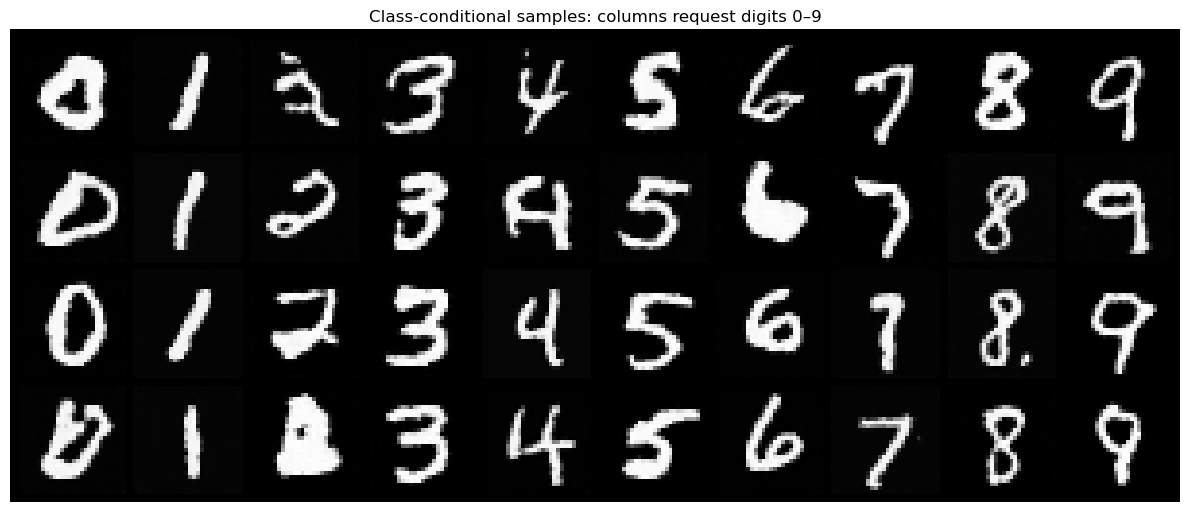

Generated shape: (40, 1, 28, 28)


In [56]:
generation_labels = torch.arange(10, device=device).repeat(4)  # One requested digit per column.
mnist_generated = sample(mnist_model, mnist_diffusion, labels=generation_labels)
show_images(mnist_generated, nrow=10, title="Class-conditional samples: columns request digits 0–9")
print(f"Generated shape: {tuple(mnist_generated.shape)}")


#### Генерация выбранной цифры

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

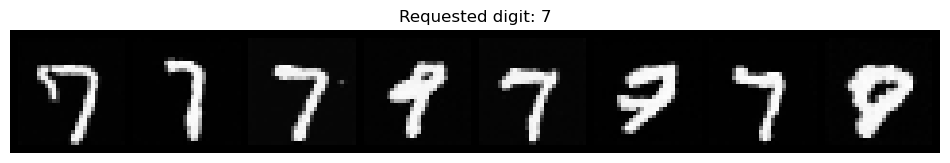

In [58]:
target_digit = 7  # Change this to request another digit.
chosen_samples = sample(mnist_model, mnist_diffusion, labels=[target_digit] * 8)
show_images(chosen_samples, nrow=8, title=f"Requested digit: {target_digit}")


<div style="background-color:#eefbf0; border-left:4px solid #22a55e; padding:10px 15px; border-radius:4px; margin:10px 0;">

**Основные выводы:**


- Прямой процесс фиксирован и получаем $\mathbf{x}_t$ напрямую из данных.
- Targets создаём сами: это шум, которым зашумляли изображения.
- Одна сеть работает для всех времён: U-Net получает зашумлённую картинку, время $t$ и класс цифры $y$.
- Во время обучения делаем один проход сети, во время генерации выполняем всю обратную цепь.
- Предсказанный шум задаёт среднее перехода, дисперсию фиксируем.

</div>
